# Monthly Price Forecasting — Internship Project

## 1. Project Overview

### Business Objective
The objective of this project is to analyze historical monthly price data
and forecast the average monthly price for the next 12 months.

### Project Workflow
1. Data understanding and validation
2. Data cleaning and preprocessing
3. Exploratory Data Analysis (EDA)
4. Time-series analysis
5. Forecasting model development
6. Model evaluation and comparison
7. Future price forecasting
8. Business recommendations
9. Production deployment architecture
10. Model monitoring

### Dataset
- File: price_data.csv
- Date column: date
- Target variable: avg_monthly_price

In [1]:
# 1. IMPORTNG REQUIRED LIBRARIES
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")
print("Python Version:", sys.version)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Python Version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Pandas Version: 3.1.0
NumPy Version: 2.5.4


In [11]:
# 2. LOAD THE DATASET
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "price_data.csv"

print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

Project Root: d:\BECAME_DEVELOPER\PriceForecastingW2A
Dataset Path: d:\BECAME_DEVELOPER\PriceForecastingW2A\data\raw\price_data.csv


In [12]:
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (249, 2)


In [4]:
# Dataset Understanding
print("FIRST 10 RECORDS")
display(df.head(10))

print("\nLAST 10 RECORDS")
display(df.tail(10))

FIRST 10 RECORDS


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876
5,2005-06-01,5058
6,2005-07-01,4919
7,2005-08-01,5149
8,2005-09-01,4899
9,2005-10-01,4562



LAST 10 RECORDS


,date,avg_monthly_price
239,2024-12-01,12250
240,2025-01-01,11313
241,2025-02-01,11313
242,2025-03-01,14188
243,2025-04-01,14263
244,2025-05-01,14263
245,2025-06-01,14263
246,2025-07-01,16000
247,2025-08-01,15025
248,2025-09-01,15750


In [5]:
print("\nCOLUMN NAMES")
print(df.columns.tolist())


COLUMN NAMES
['date', 'avg_monthly_price']


In [6]:
print("\nDATA TYPES")
print(df.dtypes)


DATA TYPES
date                   str
avg_monthly_price    int64
dtype: object


In [8]:
print("\nDATASET INFORMATION")
df.info()


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               249 non-null    str  
 1   avg_monthly_price  249 non-null    int64
dtypes: int64(1), str(1)
memory usage: 4.0 KB


In [9]:
display(df.describe(include="all"))

,date,avg_monthly_price
count,249,249.000000
unique,249,NaN
top,2005-01-01,NaN
freq,1,NaN
mean,NaN,7918.891566
std,NaN,2804.992684
min,NaN,3500.000000
25%,NaN,6123.000000
50%,NaN,7250.000000
75%,NaN,9783.000000


#### Data Cleaning and sort

- Time-series models require dates in a proper datetime format.

In [14]:
# convert date
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed.")
print(df.dtypes)

Date conversion completed.
date                 datetime64[us]
avg_monthly_price             int64
dtype: object


In [15]:
print("Missing values:")
display(df.isnull().sum())

Missing values:


date                 0
avg_monthly_price    0
dtype: int64

In [16]:

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["date"].duplicated().sum())


Duplicate rows: 0
Duplicate dates: 0


In [17]:
print("\nInvalid dates:", df["date"].isna().sum())
print("Invalid prices:", df["avg_monthly_price"].isna().sum())


Invalid dates: 0
Invalid prices: 0


In [18]:
print("Zero or negative prices:",
      (df["avg_monthly_price"] <= 0).sum())

Zero or negative prices: 0


In [19]:
print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())


Date range:
Start: 2005-01-01 00:00:00
End: 2025-09-01 00:00:00


In [20]:
print("\nPrice range:")
print("Minimum:", df["avg_monthly_price"].min())
print("Maximum:", df["avg_monthly_price"].max())


Price range:
Minimum: 3500
Maximum: 16163


In [21]:
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="MS"
)

actual_dates = pd.DatetimeIndex(df["date"])

missing_months = expected_dates.difference(actual_dates)

print("Expected monthly records:", len(expected_dates))
print("Actual monthly records:", len(actual_dates))
print("Missing months:", len(missing_months))

if len(missing_months) > 0:
    print(missing_months)
else:
    print("All months are present.")

Expected monthly records: 249
Actual monthly records: 249
Missing months: 0
All months are present.


- Above the data shows as contain 1st of every month from 2005 to 2025.
- (20 yrs * 12) + 9 = 249
- Missing months can affect forecasting accuracy and seasonal analysis.

## Exploratory Data Analysis

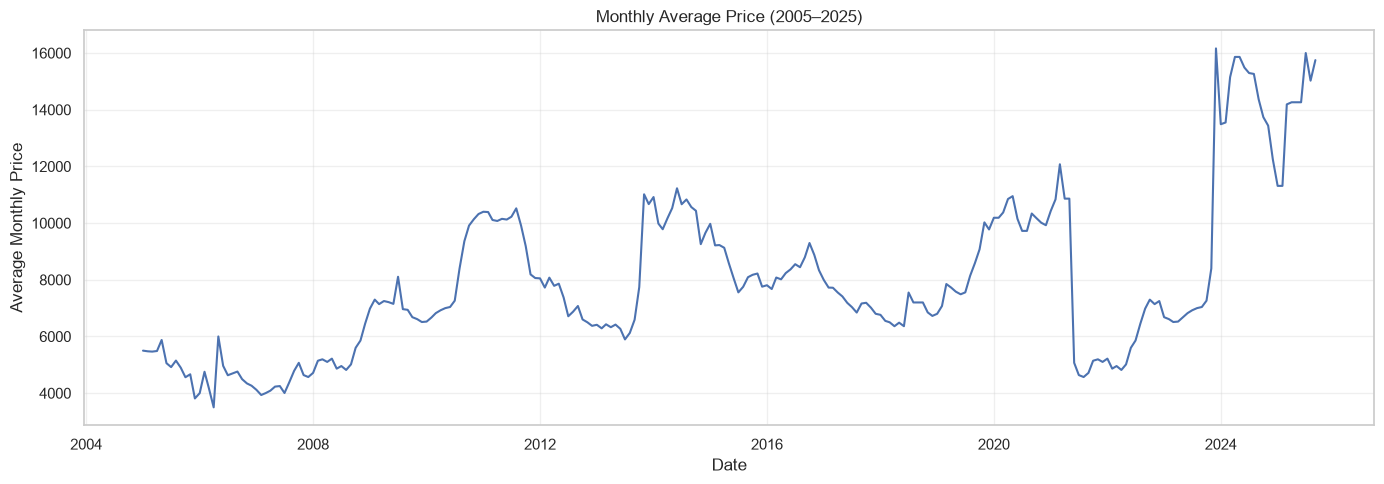

In [22]:
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["avg_monthly_price"], linewidth=1.5)

plt.title("Monthly Average Price (2005–2025)")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

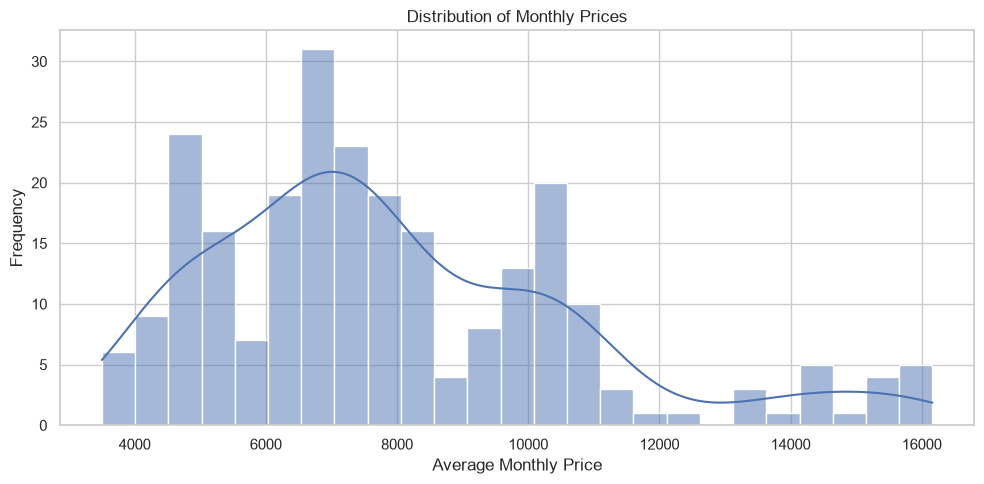

In [23]:
# checking price dist
plt.figure(figsize=(10, 5))

sns.histplot(df["avg_monthly_price"], bins=25, kde=True)

plt.title("Distribution of Monthly Prices")
plt.xlabel("Average Monthly Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# calculate yearly average
df["year"] = df["date"].dt.year

yearly_avg = df.groupby("year")["avg_monthly_price"].mean()

display(yearly_avg.round(2).to_frame("Average Price"))

,Average Price
year,
2005,5072.50
2006,4548.75
2007,4339.92
2008,5244.50
2009,7070.67
2010,8031.25
2011,9778.83
2012,7251.00
2013,7181.92


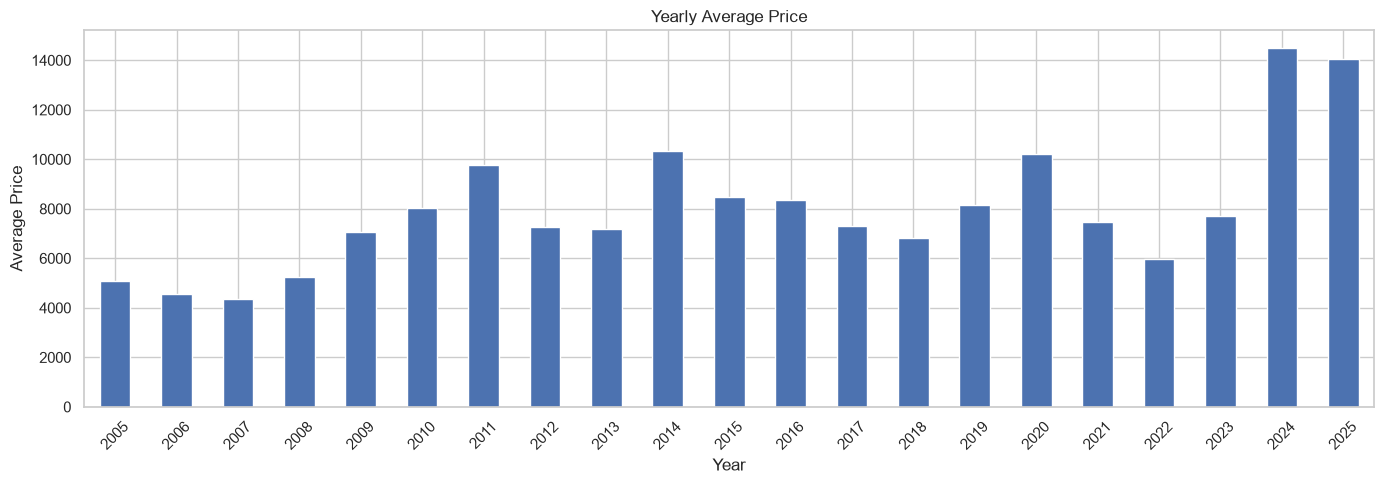

In [25]:
plt.figure(figsize=(14, 5))

yearly_avg.plot(kind="bar")

plt.title("Yearly Average Price")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
# calculate monthly pct change
df["monthly_change"] = df["avg_monthly_price"].pct_change() * 100

display(
    df[["date", "avg_monthly_price", "monthly_change"]].tail(15)
)

,date,avg_monthly_price,monthly_change
234,2024-07-01,15294,-1.252583
235,2024-08-01,15263,-0.202694
236,2024-09-01,14363,-5.896613
237,2024-10-01,13738,-4.351459
238,2024-11-01,13438,-2.183724
239,2024-12-01,12250,-8.840601
240,2025-01-01,11313,-7.648980
241,2025-02-01,11313,0.000000
242,2025-03-01,14188,25.413241
243,2025-04-01,14263,0.528616


- Don't remove any outliers yet.


### EDA Observations:
- Prices generally increased between 2005 and 2025, but there are periods of decline.
- noticeable changes around 2011, 2014, 2021 and 2024.
- The histogram is right-skewed, with a smaller number of observations at higher price levels.
- March 2025 recorded a 25.41% increase, while July 2025 recorded a 12.18% increase.
- 2025 contains only January–September data, so its yearly average is not directly comparable with complete years.
- Further analysis is required.

## Outlier and anomaly analysis


In [28]:
change_stats = df["monthly_change"].dropna()

median_change = change_stats.median()
mad = (change_stats - median_change).abs().median()

if mad > 0:
    df["modified_z_score"] = (
        0.6745 * (df["monthly_change"] - median_change) / mad
    )
else:
    df["modified_z_score"] = np.nan

df["anomaly_flag"] = df["modified_z_score"].abs() > 3.5

print("Median monthly change:", round(median_change, 2))
print("MAD:", round(mad, 2))
print("Potential anomalies:", df["anomaly_flag"].sum())

display(
    df.loc[
        df["anomaly_flag"],
        ["date", "avg_monthly_price", "monthly_change", "modified_z_score"]
    ]
)

Median monthly change: 0.0
MAD: 2.9
Potential anomalies: 14


,date,avg_monthly_price,monthly_change,modified_z_score
11,2005-12-01,3813,-18.263666,-4.252146
13,2006-02-01,4755,18.875000,4.394477
15,2006-04-01,3500,-16.187739,-3.768829
16,2006-05-01,6000,71.428571,16.629998
17,2006-06-01,4964,-17.266667,-4.020025
67,2010-08-01,8400,15.670614,3.648432
105,2013-10-01,7744,17.511381,4.076999
106,2013-11-01,11016,42.252066,9.837125
162,2018-07-01,7550,18.673373,4.347534
197,2021-06-01,5070,-53.327810,-12.415779


- Modified Z-score uses the median and median absolute deviation, making it less sensitive to extreme changes than a standard Z-score
- some large movements are followed by movements in the opposite direction. This may indicate temporary price shocks

In [29]:
largest_changes = df.loc[
    df["monthly_change"].abs().nlargest(10).index,
    ["date", "avg_monthly_price", "monthly_change"]
].sort_values("monthly_change", key=abs, ascending=False)

display(largest_changes)

,date,avg_monthly_price,monthly_change
227,2023-12-01,16163,92.416667
16,2006-05-01,6000,71.428571
197,2021-06-01,5070,-53.327810
106,2013-11-01,11016,42.252066
242,2025-03-01,14188,25.413241
13,2006-02-01,4755,18.875000
162,2018-07-01,7550,18.673373
11,2005-12-01,3813,-18.263666
105,2013-10-01,7744,17.511381
17,2006-06-01,4964,-17.266667


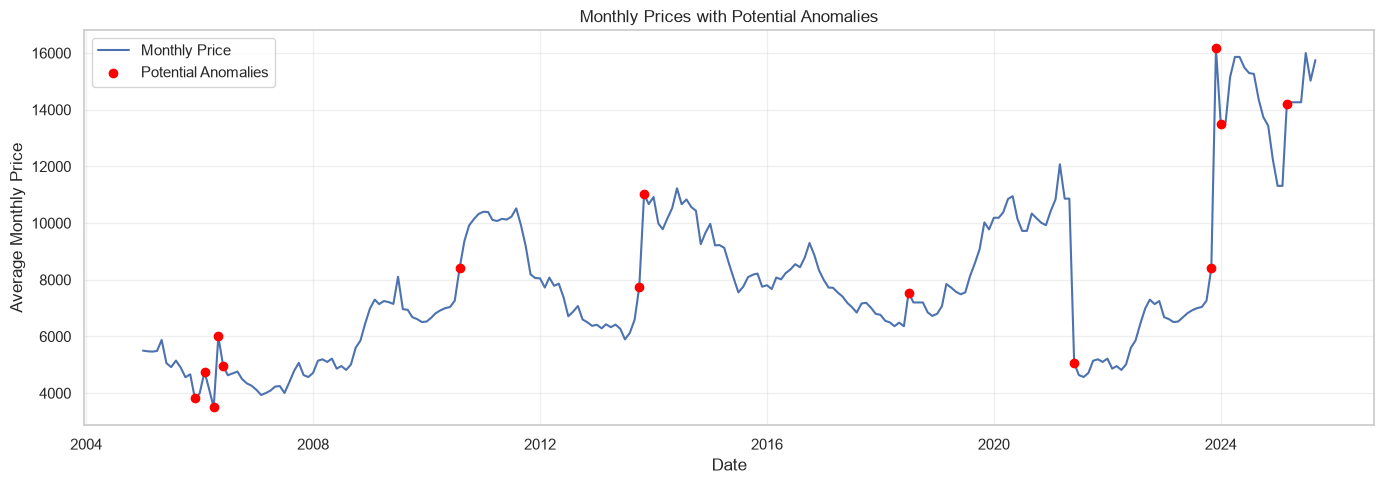

In [30]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    label="Monthly Price"
)

anomalies = df[df["anomaly_flag"]]

plt.scatter(
    anomalies["date"],
    anomalies["avg_monthly_price"],
    color="red",
    label="Potential Anomalies",
    zorder=3
)

plt.title("Monthly Prices with Potential Anomalies")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Anomaly Analysis

- 14 potential anomalies were identified using the Modified Z-score method.
- Major price movements occurred in 2006, 2013, 2021, 2023 and 2025.
- Some sharp movements were followed by reversals.
- All original observations are retained for forecasting.

## Time-series preparation

In [31]:
# creating time series
ts = df.set_index("date")["avg_monthly_price"].asfreq("MS")

print("Time series created.")
print("Frequency:", ts.index.freq)
print("Observations:", len(ts))
print("Missing values:", ts.isna().sum())

display(ts.head())
display(ts.tail())

Time series created.
Frequency: <MonthBegin>
Observations: 249
Missing values: 0


date
2005-01-01    5500
2005-02-01    5476
2005-03-01    5466
2005-04-01    5487
2005-05-01    5876
Freq: MS, Name: avg_monthly_price, dtype: int64

date
2025-05-01    14263
2025-06-01    14263
2025-07-01    16000
2025-08-01    15025
2025-09-01    15750
Freq: MS, Name: avg_monthly_price, dtype: int64

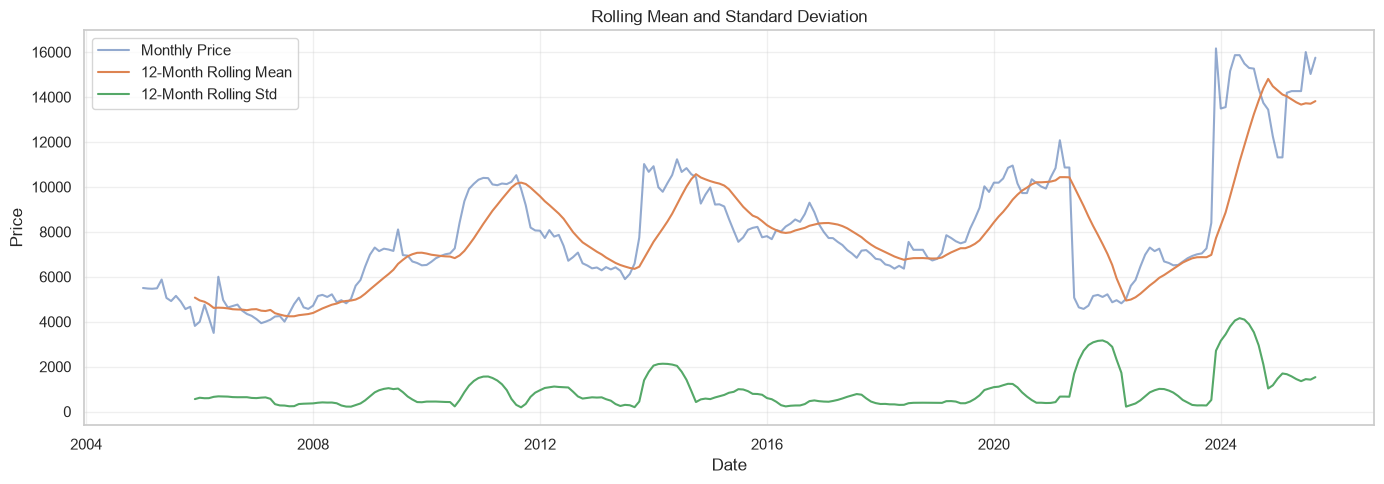

In [ ]:
# rolling mean and standard deviation
rolling_mean = ts.rolling(window=12).mean()
rolling_std = ts.rolling(window=12).std()

plt.figure(figsize=(14, 5))

plt.plot(ts, label="Monthly Price", alpha=0.6)
plt.plot(rolling_mean, label="12-Month Rolling Mean")
plt.plot(rolling_std, label="12-Month Rolling Std")

plt.title("Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# monthly seasonality
monthly_avg = df.groupby(
    df["date"].dt.month
)["avg_monthly_price"].mean()

display(monthly_avg.round(2).to_frame("Average Price"))

,Average Price
date,
1,7822.48
2,7774.67
3,8086.86
4,8032.43
5,8210.24
6,7770.19
7,7812.67
8,7865.52
9,8044.38


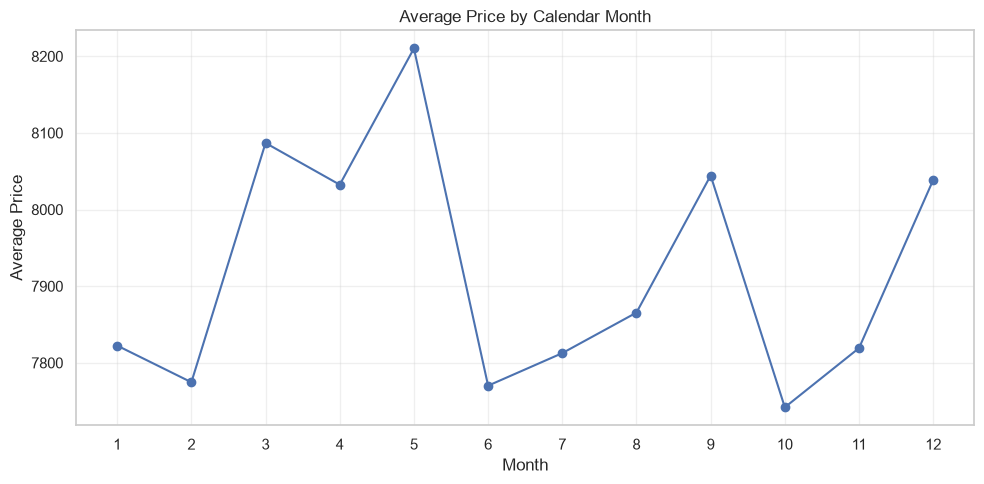

In [34]:
plt.figure(figsize=(10, 5))

monthly_avg.plot(marker="o")

plt.title("Average Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
train = ts.iloc[:-12]
test = ts.iloc[-12:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Training records:", len(train))

print("\nTesting period:", test.index.min(), "to", test.index.max())
print("Testing records:", len(test))

Training period: 2005-01-01 00:00:00 to 2024-09-01 00:00:00
Training records: 237

Testing period: 2024-10-01 00:00:00 to 2025-09-01 00:00:00
Testing records: 12


### Time Series Observations

- The series shows an overall upward trend.
- Price variability changes over time.
- Monthly averages show some seasonal differences.
- Training data contains 237 observations.
- Testing data contains the final 12 observations.

## Time-series decomposition and stationarity

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

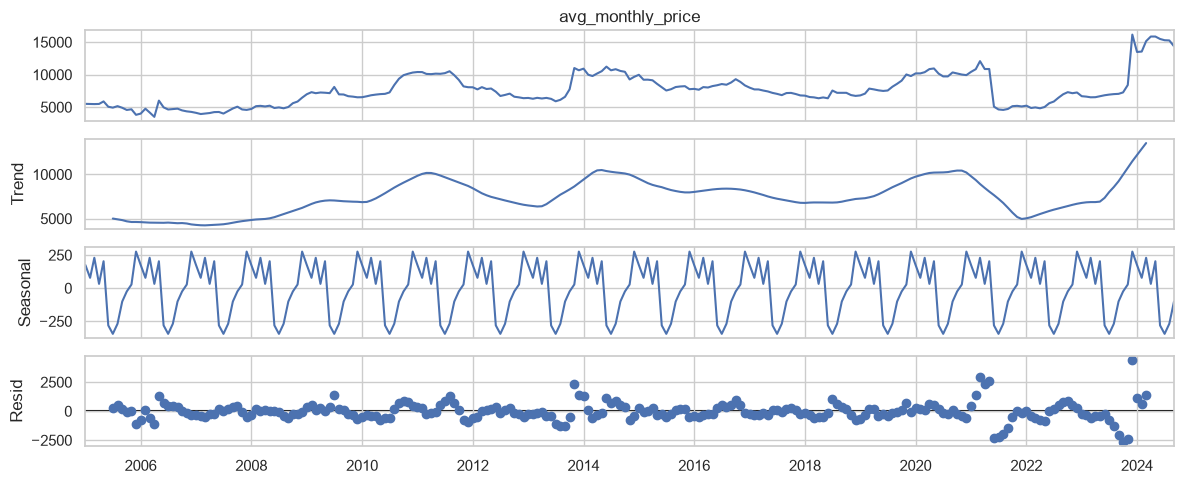

In [37]:
decomposition = seasonal_decompose(
    train,
    model="additive",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

- Trend: long-term price movement.
- Seasonal: repeating annual pattern.
- Residual: remaining unexplained variation

In [38]:
adf_result = adfuller(train)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: -1.898
p-value: 0.333
The series is non-stationary.


- require differencing when the series is non-stationary

In [39]:
train_diff = train.diff().dropna()

adf_diff = adfuller(train_diff)

print("ADF Statistic:", round(adf_diff[0], 4))
print("p-value:", round(adf_diff[1], 4))

if adf_diff[1] <= 0.05:
    print("Differenced series is stationary.")
else:
    print("Differenced series is non-stationary.")

ADF Statistic: -15.7668
p-value: 0.0
Differenced series is stationary.


|Test|Result|Interpretation|
|---|---|---|
|Original ADF p-value|0.333|Non-stationary|
|First-differenced ADF p-value|0.000|Stationary|

### Stationarity and Decomposition

- The original series is non-stationary.
- First-order differencing makes the series stationary.
- The decomposition shows a changing trend and repeating seasonal component.
- ARIMA models with d=1 will be considered.

## Forecasting Models

### Baseline Models

Naive, Seasonal Naive, Moving Average and Drift models are used as benchmarks.

In [40]:
# Baseline forecasts

horizon = len(test)

forecasts = {}

# Naive
forecasts["Naive"] = np.repeat(train.iloc[-1], horizon)

# Seasonal Naive
forecasts["Seasonal Naive"] = np.tile(
    train.iloc[-12:].values,
    int(np.ceil(horizon / 12))
)[:horizon]

# Moving Average - 3 months
forecasts["MA3"] = np.repeat(train.iloc[-3:].mean(), horizon)

# Moving Average - 6 months
forecasts["MA6"] = np.repeat(train.iloc[-6:].mean(), horizon)

# Drift
drift = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)

forecasts["Drift"] = (
    train.iloc[-1] + drift * np.arange(1, horizon + 1)
)

print("Baseline forecasts generated.")

Baseline forecasts generated.


- Naive: uses the latest observed price for every forecast month.
- Seasonal Naive: repeats the prices from the previous 12 months.
- MA3 and MA6: use the average of the latest three or six months.
- Drift: extends the average historical direction of change.

In [41]:
# Calculate forecast errors
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    smape = np.mean(
        200 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted))
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape
    }


baseline_results = []

for model_name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    baseline_results.append({
        "Model": model_name,
        **metrics
    })

baseline_metrics = pd.DataFrame(baseline_results)
baseline_metrics = baseline_metrics.sort_values("MAE")

display(baseline_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
4,Drift,1197.89,1588.80,8.79
2,MA3,1465.50,1868.30,10.59
3,MA6,1711.78,2126.24,12.20
1,Seasonal Naive,2296.42,2921.06,18.52


- sMAPE: percentage-based forecast error
- Naive is currently the best baseline model. It performs slightly better than Drift on all three metrics

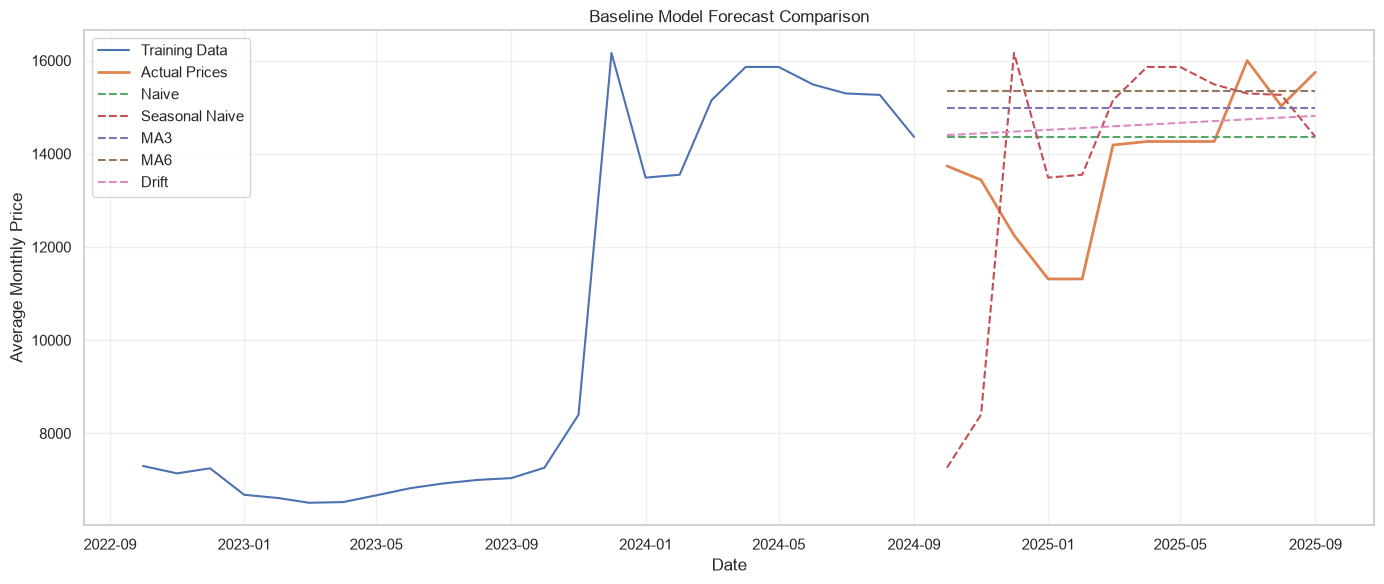

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(train.tail(24), label="Training Data")
plt.plot(test, label="Actual Prices", linewidth=2)

for model_name, prediction in forecasts.items():
    plt.plot(
        test.index,
        prediction,
        linestyle="--",
        label=model_name
    )

plt.title("Baseline Model Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Advanced forecasting models

In [46]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [47]:
ets_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

ets_forecast = ets_model.forecast(12)

forecasts["ETS"] = ets_forecast.values

display(ets_forecast)

2024-10-01    14419.646173
2024-11-01    14367.901331
2024-12-01    14567.185037
2025-01-01    14451.135134
2025-02-01    14365.435760
2025-03-01    14573.401023
2025-04-01    14521.067346
2025-05-01    14720.085266
2025-06-01    14281.387674
2025-07-01    14250.668730
2025-08-01    14317.685508
2025-09-01    14365.793486
Freq: MS, dtype: float64

In [48]:
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=12)

forecasts["SARIMA"] = sarima_forecast.values

display(sarima_forecast)

2024-10-01    14688.166300
2024-11-01    14681.328043
2024-12-01    15287.891359
2025-01-01    15047.170614
2025-02-01    15065.191301
2025-03-01    15318.715749
2025-04-01    15308.129056
2025-05-01    15335.791322
2025-06-01    14723.573967
2025-07-01    14654.987518
2025-08-01    14816.360197
2025-09-01    14946.431862
Freq: MS, Name: predicted_mean, dtype: float64

In [49]:
all_results = []

for model_name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    all_results.append({
        "Model": model_name,
        **metrics
    })

all_metrics = pd.DataFrame(all_results)

all_metrics = all_metrics.sort_values("MAE").reset_index(drop=True)

display(all_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
1,Drift,1197.89,1588.80,8.79
2,ETS,1256.59,1626.98,9.19
3,MA3,1465.50,1868.30,10.59
4,SARIMA,1565.35,1956.45,11.25
5,MA6,1711.78,2126.24,12.20
6,Seasonal Naive,2296.42,2921.06,18.52


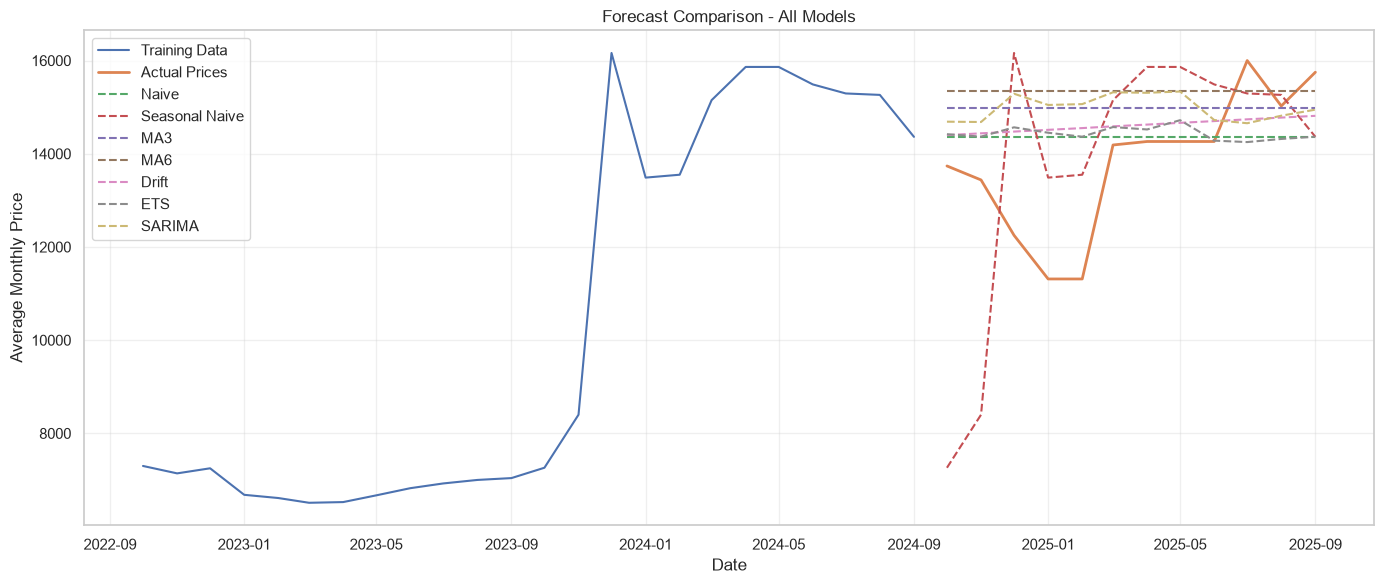

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(train.tail(24), label="Training Data")
plt.plot(test, label="Actual Prices", linewidth=2)

for model_name, prediction in forecasts.items():
    plt.plot(
        test.index,
        prediction,
        linestyle="--",
        label=model_name
    )

plt.title("Forecast Comparison - All Models")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Naive currently performs best.
- Drift and ETS are reasonably close to Naive.
- SARIMA is not outperforming the simpler models.

## Feature Engineering

In [51]:
ml_data = pd.DataFrame(index=ts.index)

ml_data["price"] = ts

# Calendar features
ml_data["month"] = ml_data.index.month
ml_data["year"] = ml_data.index.year

# Lag features
for lag in [1, 2, 3, 6, 12]:
    ml_data[f"lag_{lag}"] = ml_data["price"].shift(lag)

# Rolling features using previous months only
for window in [3, 6, 12]:
    ml_data[f"rolling_mean_{window}"] = (
        ml_data["price"].shift(1).rolling(window).mean()
    )

ml_data["rolling_std_3"] = (
    ml_data["price"].shift(1).rolling(3).std()
)

ml_data = ml_data.dropna()

display(ml_data.head())
print("Feature dataset shape:", ml_data.shape)

,price,month,year,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3
date,,,,,,,,,,,,
2006-01-01,4000,1,2006,3813.0,4665.0,4562.0,4919.0,5500.0,4346.666667,4667.833333,5072.500000,465.029390
2006-02-01,4755,2,2006,4000.0,3813.0,4665.0,5149.0,5476.0,4159.333333,4514.666667,4947.500000,447.790502
2006-03-01,4176,3,2006,4755.0,4000.0,3813.0,4899.0,5466.0,4189.333333,4449.000000,4887.416667,498.724707
2006-04-01,3500,4,2006,4176.0,4755.0,4000.0,4562.0,5487.0,4310.333333,4328.500000,4779.916667,395.019409
2006-05-01,6000,5,2006,3500.0,4176.0,4755.0,4665.0,5876.0,4143.666667,4151.500000,4614.333333,628.124457


Feature dataset shape: (237, 12)


In [52]:
X = ml_data.drop(columns=["price"])
y = ml_data["price"]

X_train = X.loc[train.index.intersection(X.index)]
y_train = y.loc[X_train.index]

X_test = X.loc[test.index.intersection(X.index)]
y_test = y.loc[X_test.index]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training features: (225, 11)
Testing features: (12, 11)
Training period: 2006-01-01 00:00:00 to 2024-09-01 00:00:00
Testing period: 2024-10-01 00:00:00 to 2025-09-01 00:00:00


In [55]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [56]:
def create_future_features(history, date):
    features = {
        "month": date.month,
        "year": date.year
    }

    for lag in [1, 2, 3, 6, 12]:
        features[f"lag_{lag}"] = history.iloc[-lag]

    for window in [3, 6, 12]:
        features[f"rolling_mean_{window}"] = (
            history.iloc[-window:].mean()
        )

    features["rolling_std_3"] = history.iloc[-3:].std()

    return pd.DataFrame([features])

In [57]:
def recursive_forecast(model, history, forecast_dates):
    history = history.copy()
    predictions = []

    for date in forecast_dates:
        X_future = create_future_features(history, date)

        prediction = model.predict(X_future)[0]

        predictions.append(prediction)

        history.loc[date] = prediction

    return np.array(predictions)

In [59]:
# train Random forest
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_forecast = recursive_forecast(
    rf_model,
    train,
    test.index
)

forecasts["Random Forest"] = rf_forecast

print("Random Forest training completed.")

Random Forest training completed.


In [60]:
# train XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_forecast = recursive_forecast(
    xgb_model,
    train,
    test.index
)

forecasts["XGBoost"] = xgb_forecast

print("XGBoost training completed.")

XGBoost training completed.


In [61]:
# evaluate
ml_results = []

for name, prediction in {
    "Random Forest": rf_forecast,
    "XGBoost": xgb_forecast
}.items():

    metrics = calculate_metrics(test.values, prediction)

    ml_results.append({
        "Model": name,
        **metrics
    })

ml_metrics = pd.DataFrame(ml_results)

display(ml_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Random Forest,1497.18,1845.10,10.80
1,XGBoost,1218.33,1524.24,8.92


In [62]:
all_results = []

for name, prediction in forecasts.items():
    metrics = calculate_metrics(test.values, prediction)

    all_results.append({
        "Model": name,
        **metrics
    })

all_metrics = pd.DataFrame(all_results)
all_metrics = all_metrics.sort_values("MAE").reset_index(drop=True)

display(all_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Naive,1160.33,1565.74,8.53
1,Drift,1197.89,1588.80,8.79
2,XGBoost,1218.33,1524.24,8.92
3,ETS,1256.59,1626.98,9.19
4,MA3,1465.50,1868.30,10.59
5,Random Forest,1497.18,1845.10,10.80
6,SARIMA,1565.35,1956.45,11.25
7,MA6,1711.78,2126.24,12.20
8,Seasonal Naive,2296.42,2921.06,18.52


- Naive has the lowest MAE and sMAPE.
- Random Forest has not improved on the simpler models.

## Model Validation
Expanding Window-Backtesting

In [64]:
def prepare_ml_features(history):
    data = pd.DataFrame({"price": history})

    data["month"] = data.index.month
    data["year"] = data.index.year

    for lag in [1, 2, 3, 6, 12]:
        data[f"lag_{lag}"] = data["price"].shift(lag)

    for window in [3, 6, 12]:
        data[f"rolling_mean_{window}"] = (
            data["price"].shift(1).rolling(window).mean()
        )

    data["rolling_std_3"] = (
        data["price"].shift(1).rolling(3).std()
    )

    return data.dropna()

In [76]:
backtest_results = []
backtest_predictions = []

cutoff_dates = pd.date_range(
    start="2017-09-01", # sept 2017
    end="2023-09-01", # sept 2023
    freq="12MS"
)

for cutoff in cutoff_dates:

    cutoff_pos = ts.index.get_loc(cutoff)

    history = ts.iloc[:cutoff_pos + 1].copy()
    actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

    if len(actual) != 12:
        continue

    horizon = len(actual)
    predictions = {}

    # Baseline models
    predictions["Naive"] = np.repeat(history.iloc[-1], horizon)

    predictions["Seasonal Naive"] = np.tile(
        history.iloc[-12:].values, 1
    )

    predictions["MA3"] = np.repeat(history.iloc[-3:].mean(), horizon)
    predictions["MA6"] = np.repeat(history.iloc[-6:].mean(), horizon)

    drift = (
        (history.iloc[-1] - history.iloc[0]) /
        (len(history) - 1)
    )

    predictions["Drift"] = (
        history.iloc[-1] + drift * np.arange(1, horizon + 1)
    )

    # ETS
    ets = ExponentialSmoothing(
        history,
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit()

    predictions["ETS"] = ets.forecast(horizon).values

    # SARIMA
    sarima = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    predictions["SARIMA"] = sarima.forecast(horizon).values

    # Machine learning features
    feature_data = prepare_ml_features(history)

    X_fold = feature_data.drop(columns=["price"])
    y_fold = feature_data["price"]

    rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=5,
        random_state=42
    )

    rf.fit(X_fold, y_fold)

    predictions["Random Forest"] = recursive_forecast(
        rf, history, actual.index
    )

    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb.fit(X_fold, y_fold)

    predictions["XGBoost"] = recursive_forecast(
        xgb, history, actual.index
    )

    # Evaluate each model
    for name, prediction in predictions.items():

        metrics = calculate_metrics(actual.values, prediction)

        backtest_results.append({
            "Cutoff": cutoff,
            "Model": name,
            **metrics
        })

        for date, actual_value, predicted_value in zip(
            actual.index, actual.values, prediction
        ):
            backtest_predictions.append({
                "Cutoff": cutoff,
                "Date": date,
                "Model": name,
                "Actual": actual_value,
                "Predicted": predicted_value,
                "Error": predicted_value - actual_value
            })

    print("Completed:", cutoff.strftime("%Y-%m"))

Completed: 2017-09
Completed: 2018-09
Completed: 2019-09
Completed: 2020-09
Completed: 2021-09
Completed: 2022-09
Completed: 2023-09


In [77]:
# calculate avg backtesting perf
backtest_df = pd.DataFrame(backtest_results)

backtest_summary = (
    backtest_df.groupby("Model")[["MAE", "RMSE", "sMAPE"]]
    .mean()
    .sort_values("MAE")
)

display(backtest_summary.round(2))

,MAE,RMSE,sMAPE
Model,,,
Drift,1764.08,2091.44,19.29
Naive,1773.93,2087.45,19.40
Random Forest,1805.50,2073.39,19.66
SARIMA,1845.38,2193.69,20.58
ETS,1855.52,2173.55,21.09
MA3,1879.03,2158.84,20.85
XGBoost,1998.88,2202.77,22.13
MA6,2147.32,2442.32,24.70
Seasonal Naive,2732.37,3109.21,32.20


- Drift has the lowest average MAE and sMAPE.
- Random Forest is competitive in backtesting
- The September 2023 cutoff produces large errors across all models

Keeping Naive and Drift as leading candidates

In [78]:
backtest_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
).round(2) 

Model,Drift,ETS,MA3,MA6,Naive,Random Forest,SARIMA,Seasonal Naive,XGBoost
Cutoff,,,,,,,,,
2017-09-01,451.47,431.48,363.31,426.50,412.75,546.62,555.22,1081.42,1206.60
2018-09-01,448.20,557.96,470.22,638.75,489.67,469.68,564.21,673.08,462.34
2019-09-01,1411.62,1479.10,2019.67,2267.67,1525.67,1580.00,1484.07,2649.00,1565.18
2020-09-01,2260.84,2199.07,2206.36,2211.53,2219.58,2269.84,2252.99,2074.58,2049.62
2021-09-01,743.93,1153.90,792.75,1385.53,718.42,493.90,866.40,4230.00,479.74
2022-09-01,271.61,389.36,443.67,1086.00,245.83,774.79,452.90,1439.58,1664.35
2023-09-01,6760.90,6777.76,6857.25,7015.25,6805.58,6503.64,6741.85,6978.92,6564.35


In [79]:
# Pooled backtesting metrics
pooled_results = []

for model_name, group in backtest_df.groupby("Model"):

    actual = []
    predicted = []

    for cutoff in group["Cutoff"]:
        cutoff_pos = ts.index.get_loc(cutoff)

        history = ts.iloc[:cutoff_pos + 1]
        actual_values = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

        # Retrieve predictions from the corresponding fold
        # We will store predictions in the next backtesting run.

    pooled_results.append({
        "Model": model_name,
        "Mean Fold MAE": group["MAE"].mean(),
        "Mean Fold RMSE": group["RMSE"].mean(),
        "Mean Fold sMAPE": group["sMAPE"].mean()
    })

pooled_summary = pd.DataFrame(pooled_results)

display(pooled_summary.round(2))

,Model,Mean Fold MAE,Mean Fold RMSE,Mean Fold sMAPE
0,Drift,1764.08,2091.44,19.29
1,ETS,1855.52,2173.55,21.09
2,MA3,1879.03,2158.84,20.85
3,MA6,2147.32,2442.32,24.70
4,Naive,1773.93,2087.45,19.40
5,Random Forest,1805.50,2073.39,19.66
6,SARIMA,1845.38,2193.69,20.58
7,Seasonal Naive,2732.37,3109.21,32.20
8,XGBoost,1998.88,2202.77,22.13


In [80]:
# Calculate pooled metrics

prediction_df = pd.DataFrame(backtest_predictions)

pooled_results = []

for model_name, group in prediction_df.groupby("Model"):

    metrics = calculate_metrics(
        group["Actual"].values,
        group["Predicted"].values
    )

    pooled_results.append({
        "Model": model_name,
        **metrics
    })

pooled_metrics = pd.DataFrame(pooled_results)

pooled_metrics = pooled_metrics.sort_values("MAE")

display(pooled_metrics.round(2))

,Model,MAE,RMSE,sMAPE
0,Drift,1764.08,3144.67,19.29
4,Naive,1773.93,3145.28,19.40
5,Random Forest,1805.50,3011.65,19.66
6,SARIMA,1845.38,3163.91,20.58
1,ETS,1855.52,3164.03,21.09
2,MA3,1879.03,3177.87,20.85
8,XGBoost,1998.88,3044.49,22.13
3,MA6,2147.32,3329.65,24.70
7,Seasonal Naive,2732.37,3803.62,32.20


- Drift has the lowest pooled MAE and sMAPE, while Random Forest has the lowest pooled RMSE.

In [81]:
# Compare model consistency

consistency_metrics = (
    backtest_df.groupby("Model")["MAE"]
    .agg(
        Mean_MAE="mean",
        Median_MAE="median",
        Std_MAE="std",
        Best_MAE="min",
        Worst_MAE="max"
    )
)

consistency_metrics["MAE_Variation"] = (
    consistency_metrics["Std_MAE"] /
    consistency_metrics["Mean_MAE"] * 100
)

display(
    consistency_metrics.sort_values("Mean_MAE").round(2)
)

,Mean_MAE,Median_MAE,Std_MAE,Best_MAE,Worst_MAE,MAE_Variation
Model,,,,,,
Drift,1764.08,743.93,2311.63,271.61,6760.90,131.04
Naive,1773.93,718.42,2328.42,245.83,6805.58,131.26
Random Forest,1805.50,774.79,2179.10,469.68,6503.64,120.69
SARIMA,1845.38,866.40,2253.72,452.90,6741.85,122.13
ETS,1855.52,1153.90,2267.22,389.36,6777.76,122.19
MA3,1879.03,792.75,2324.94,363.31,6857.25,123.73
XGBoost,1998.88,1565.18,2099.31,462.34,6564.35,105.02
MA6,2147.32,1385.53,2260.50,426.50,7015.25,105.27
Seasonal Naive,2732.37,2074.58,2211.84,673.08,6978.92,80.95


In [82]:
# counting the best model in each fold
fold_winners = (
    backtest_df.loc[
        backtest_df.groupby("Cutoff")["MAE"].idxmin(),
        ["Cutoff", "Model", "MAE"]
    ]
    .sort_values("Cutoff")
)

display(fold_winners)

win_counts = (
    fold_winners["Model"]
    .value_counts()
    .rename("Fold Wins")
    .to_frame()
)

display(win_counts)

,Cutoff,Model,MAE
2,2017-09-01,MA3,363.305556
13,2018-09-01,Drift,448.203252
22,2019-09-01,Drift,1411.621212
35,2020-09-01,XGBoost,2049.622274
44,2021-09-01,XGBoost,479.736125
45,2022-09-01,Naive,245.833333
61,2023-09-01,Random Forest,6503.641040


,Fold Wins
Model,
Drift,2
XGBoost,2
MA3,1
Naive,1
Random Forest,1


- Drift and XGBoost tie on fold wins, but Drift has better average MAE.

In [83]:
# calculate forecast bias
bias_summary = (
    prediction_df.groupby("Model")["Error"]
    .agg(
        Mean_Bias="mean",
        Median_Bias="median"
    )
)

display(bias_summary.round(2))

,Mean_Bias,Median_Bias
Model,,
Drift,-961.70,-287.83
ETS,-1067.18,-490.62
MA3,-1261.33,-518.33
MA6,-1092.00,-661.83
Naive,-1030.90,-337.00
Random Forest,-900.46,-196.82
SARIMA,-987.77,-344.56
Seasonal Naive,-869.13,-1081.50
XGBoost,-772.47,-102.26


- Positive bias: model tends to overpredict.
- Negative bias: model tends to underpredict.
- Bias near zero: little average directional error.

This indicates systematic underprediction across these backtesting periods. This is particularly important for business decisions involving procurement budgets.

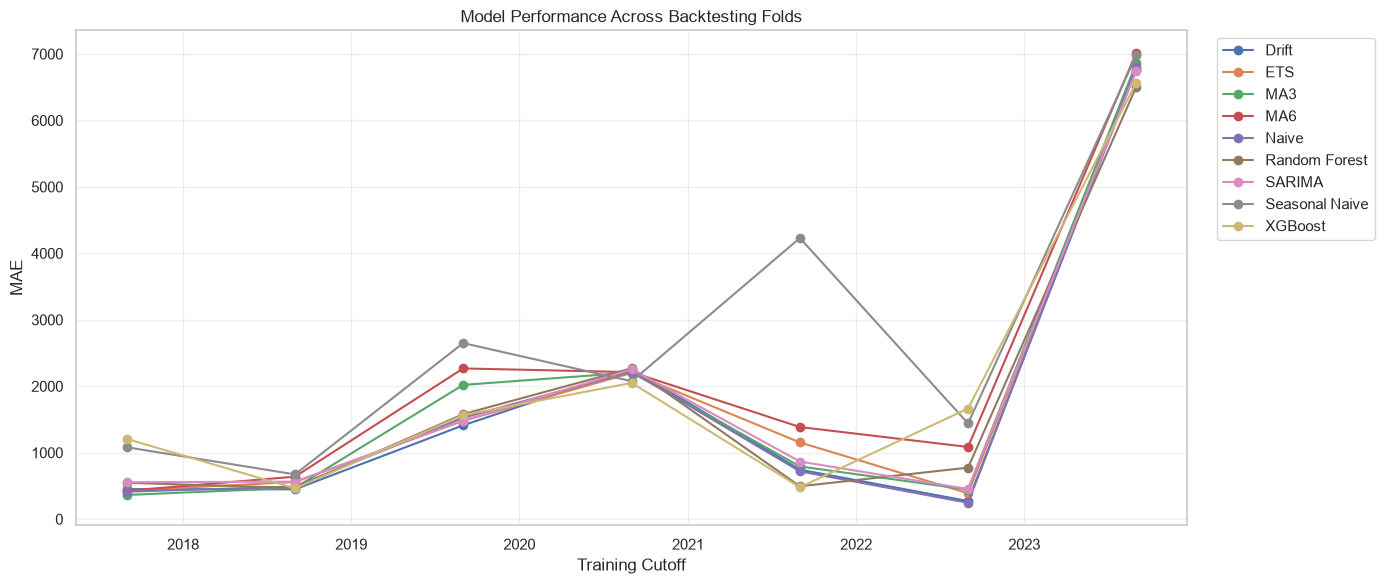

In [85]:
# Compare MAE across backtesting folds

mae_pivot = backtest_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
)

plt.figure(figsize=(14, 6))

for model_name in mae_pivot.columns:
    plt.plot(
        mae_pivot.index,
        mae_pivot[model_name],
        marker="o",
        label=model_name
    )

plt.title("Model Performance Across Backtesting Folds")
plt.xlabel("Training Cutoff")
plt.ylabel("MAE")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [69]:
df.head()

,date,avg_monthly_price,year,monthly_change,modified_z_score,anomaly_flag
0,2005-01-01,5500,2005,NaN,NaN,False
1,2005-02-01,5476,2005,-0.436364,-0.101594,False
2,2005-03-01,5466,2005,-0.182615,-0.042516,False
3,2005-04-01,5487,2005,0.384193,0.089448,False
4,2005-05-01,5876,2005,7.089484,1.650574,False


### Model Selection

Drift achieved the lowest average backtesting MAE of 1764.08
and sMAPE of 19.29%.

Naive achieved slightly better performance on the final
12-month holdout, with an MAE of 1160.33.

The difference between Drift and Naive in backtesting
was small. Both models are retained as leading candidates.

Drift is selected as the primary candidate based on
backtesting performance, while Naive is retained as
a simple benchmark.

The models show considerable variation across historical
periods, so forecast uncertainty must be considered.

|Evaluation|Drift|Naive|
|---|---|---|
|Backtesting MAE|1764.08|1773.93|
|Backtesting RMSE|	2091.44|	2087.45|
|Backtesting sMAPE|	19.29|	19.40|
|Holdout MAE|	1197.89|	1160.33|
|Holdout RMSE|	1588.80|	1565.74|
|Fold Wins|	2.00|	1.00|


## Forecast Uncertainty and Prediction Intervals

Historical out-of-sample forecast errors are used to estimate
prediction uncertainty.

In [88]:
# Analyze historical absolute forecast errors
# how large the historical prediction errors were for each model
error_summary = (
    prediction_df.groupby("Model")["Error"]
    .apply(lambda x: x.abs().describe())
    .unstack()
)

display(error_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Model,,,,,,,,
Drift,84.0,1764.08,2618.89,10.37,292.95,506.02,1532.23,9102.38
ETS,84.0,1855.52,2578.23,7.84,435.96,657.44,1718.39,9102.51
MA3,84.0,1879.03,2578.22,1.67,271.33,631.67,2094.00,9174.67
MA6,84.0,2147.32,2560.01,1.17,573.33,1221.00,2210.25,9332.67
Naive,84.0,1773.93,2612.90,0.00,310.00,514.00,1633.75,9123.00
Random Forest,84.0,1805.50,2424.92,27.69,299.89,901.37,1620.80,8858.81
SARIMA,84.0,1845.38,2585.44,6.04,354.28,699.16,1644.47,9129.62
Seasonal Naive,84.0,2732.37,2661.97,6.00,934.75,1703.00,4820.00,9338.00
XGBoost,84.0,1998.88,2310.18,37.41,489.59,1321.40,2197.94,8963.94


In [89]:
selected_models = ["Drift", "Naive"]

interval_results = []

for model_name in selected_models:

    errors = prediction_df.loc[
        prediction_df["Model"] == model_name,
        "Error"
    ].abs()

    interval_results.append({
        "Model": model_name,
        "80% Error Bound": errors.quantile(0.80),
        "95% Error Bound": errors.quantile(0.95)
    })

interval_metrics = pd.DataFrame(interval_results)

display(interval_metrics.round(2))

,Model,80% Error Bound,95% Error Bound
0,Drift,1922.58,8179.57
1,Naive,1977.00,8249.35


here the calibration will be limited, so going with ranges


In [90]:
# Create empirical prediction intervals

drift_80 = interval_metrics.loc[
    interval_metrics["Model"] == "Drift",
    "80% Error Bound"
].iloc[0]

drift_95 = interval_metrics.loc[
    interval_metrics["Model"] == "Drift",
    "95% Error Bound"
].iloc[0]

naive_80 = interval_metrics.loc[
    interval_metrics["Model"] == "Naive",
    "80% Error Bound"
].iloc[0]

naive_95 = interval_metrics.loc[
    interval_metrics["Model"] == "Naive",
    "95% Error Bound"
].iloc[0]

final_forecast["Drift Lower 80"] = (
    final_forecast["Drift Forecast"] - drift_80
)

final_forecast["Drift Upper 80"] = (
    final_forecast["Drift Forecast"] + drift_80
)

final_forecast["Drift Lower 95"] = (
    final_forecast["Drift Forecast"] - drift_95
)

final_forecast["Drift Upper 95"] = (
    final_forecast["Drift Forecast"] + drift_95
)

final_forecast["Naive Lower 80"] = (
    final_forecast["Naive Forecast"] - naive_80
)

final_forecast["Naive Upper 80"] = (
    final_forecast["Naive Forecast"] + naive_80
)

final_forecast["Naive Lower 95"] = (
    final_forecast["Naive Forecast"] - naive_95
)

final_forecast["Naive Upper 95"] = (
    final_forecast["Naive Forecast"] + naive_95
)

display(final_forecast.round(2))

,Date,Naive Forecast,Drift Forecast,Drift Change,Drift Change %,Drift Lower 80,Drift Upper 80,Drift Lower 95,Drift Upper 95,Naive Lower 80,Naive Upper 80,Naive Lower 95,Naive Upper 95
0,2025-10-01,15750,15791.33,NaN,NaN,13868.75,17713.91,7611.76,23970.90,13773.0,17727.0,7500.65,23999.35
1,2025-11-01,15750,15832.66,41.33,0.26,13910.08,17755.24,7653.09,24012.23,13773.0,17727.0,7500.65,23999.35
2,2025-12-01,15750,15873.99,41.33,0.26,13951.41,17796.57,7694.42,24053.56,13773.0,17727.0,7500.65,23999.35
3,2026-01-01,15750,15915.32,41.33,0.26,13992.74,17837.90,7735.75,24094.89,13773.0,17727.0,7500.65,23999.35
4,2026-02-01,15750,15956.65,41.33,0.26,14034.08,17879.23,7777.08,24136.22,13773.0,17727.0,7500.65,23999.35
5,2026-03-01,15750,15997.98,41.33,0.26,14075.41,17920.56,7818.42,24177.55,13773.0,17727.0,7500.65,23999.35
6,2026-04-01,15750,16039.31,41.33,0.26,14116.74,17961.89,7859.75,24218.88,13773.0,17727.0,7500.65,23999.35
7,2026-05-01,15750,16080.65,41.33,0.26,14158.07,18003.22,7901.08,24260.21,13773.0,17727.0,7500.65,23999.35
8,2026-06-01,15750,16121.98,41.33,0.26,14199.40,18044.55,7942.41,24301.54,13773.0,17727.0,7500.65,23999.35
9,2026-07-01,15750,16163.31,41.33,0.26,14240.73,18085.88,7983.74,24342.88,13773.0,17727.0,7500.65,23999.35


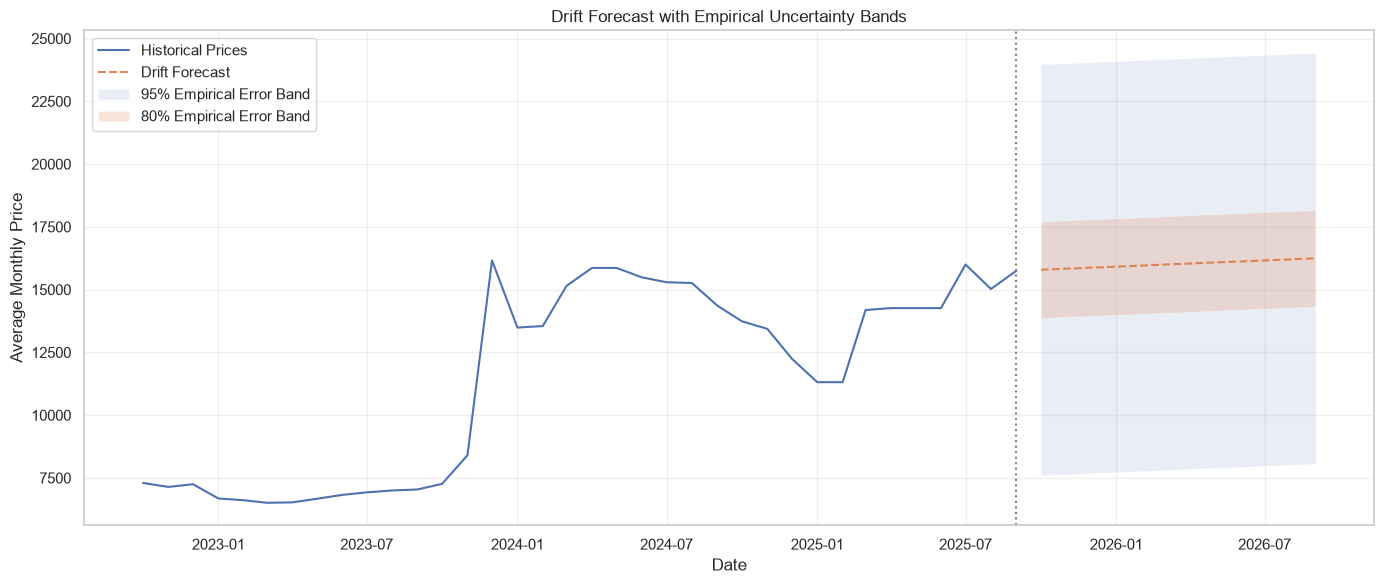

In [91]:
plt.figure(figsize=(14, 6))

plt.plot(
    ts.tail(36),
    label="Historical Prices"
)

plt.plot(
    forecast_dates,
    final_forecast["Drift Forecast"],
    label="Drift Forecast",
    linestyle="--"
)

plt.fill_between(
    forecast_dates,
    final_forecast["Drift Lower 95"],
    final_forecast["Drift Upper 95"],
    alpha=0.12,
    label="95% Empirical Error Band"
)

plt.fill_between(
    forecast_dates,
    final_forecast["Drift Lower 80"],
    final_forecast["Drift Upper 80"],
    alpha=0.22,
    label="80% Empirical Error Band"
)

plt.axvline(
    ts.index[-1],
    color="gray",
    linestyle=":"
)

plt.title("Drift Forecast with Empirical Uncertainty Bands")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
forecast_path = OUTPUT_DIR / "12_month_price_forecast.csv"

final_forecast.to_csv(forecast_path, index=False)

print("Updated forecast saved:", forecast_path)

Updated forecast saved: d:\BECAME_DEVELOPER\PriceForecastingW2A\outputs\12_month_price_forecast.csv


current method uses one error bound for all 12 forecast months
- same 80% error bound is applied to October 2025 and September 2026

But forecasting one month ahead and forecasting twelve months ahead are not necessarily equally uncertain.
calculate horizon-specific error bounds

In [93]:
# Calculate forecast horizon for each historical prediction

prediction_df["Horizon"] = (
    (prediction_df["Date"].dt.year - prediction_df["Cutoff"].dt.year) * 12
    + prediction_df["Date"].dt.month
    - prediction_df["Cutoff"].dt.month
)

# Calculate error bounds for each forecast horizon

horizon_intervals = (
    prediction_df[
        prediction_df["Model"].isin(["Drift", "Naive"])
    ]
    .groupby(["Model", "Horizon"])["Error"]
    .agg(
        Error_80=lambda x: x.abs().quantile(0.80),
        Error_95=lambda x: x.abs().quantile(0.95)
    )
    .reset_index()
)

display(horizon_intervals.round(2))

,Model,Horizon,Error_80,Error_95
0,Drift,1,408.54,458.50
1,Drift,2,1174.37,1385.21
2,Drift,3,1008.71,6711.97
3,Drift,4,1327.59,4953.30
4,Drift,5,1343.36,4986.62
5,Drift,6,1661.90,6152.64
6,Drift,7,1886.86,6784.17
7,Drift,8,1930.01,6804.09
8,Drift,9,4680.50,7520.17
9,Drift,10,5001.92,7516.88


In [94]:
# Add forecast horizon

final_forecast["Horizon"] = np.arange(1, 13)

# Apply horizon-specific bounds

for model_name in ["Drift", "Naive"]:

    bounds = (
        horizon_intervals[
            horizon_intervals["Model"] == model_name
        ]
        .set_index("Horizon")
    )

    final_forecast[f"{model_name} Lower 80"] = (
        final_forecast[f"{model_name} Forecast"]
        - final_forecast["Horizon"].map(bounds["Error_80"])
    )

    final_forecast[f"{model_name} Upper 80"] = (
        final_forecast[f"{model_name} Forecast"]
        + final_forecast["Horizon"].map(bounds["Error_80"])
    )

    final_forecast[f"{model_name} Lower 95"] = (
        final_forecast[f"{model_name} Forecast"]
        - final_forecast["Horizon"].map(bounds["Error_95"])
    )

    final_forecast[f"{model_name} Upper 95"] = (
        final_forecast[f"{model_name} Forecast"]
        + final_forecast["Horizon"].map(bounds["Error_95"])
    )

display(final_forecast.round(2))

,Date,Naive Forecast,Drift Forecast,Drift Change,Drift Change %,Drift Lower 80,Drift Upper 80,Drift Lower 95,Drift Upper 95,Naive Lower 80,Naive Upper 80,Naive Lower 95,Naive Upper 95,Horizon
0,2025-10-01,15750,15791.33,NaN,NaN,15382.79,16199.87,15332.83,16249.83,15343.2,16156.8,15280.4,16219.6,1
1,2025-11-01,15750,15832.66,41.33,0.26,14658.29,17007.03,14447.45,17217.87,14566.2,16933.8,14336.1,17163.9,2
2,2025-12-01,15750,15873.99,41.33,0.26,14865.28,16882.70,9162.02,22585.96,14705.4,16794.6,9007.8,22492.2,3
3,2026-01-01,15750,15915.32,41.33,0.26,14587.73,17242.92,10962.03,20868.62,14369.4,17130.6,10756.4,20743.6,4
4,2026-02-01,15750,15956.65,41.33,0.26,14613.29,17300.01,10970.03,20943.27,14347.4,17152.6,10713.0,20787.0,5
5,2026-03-01,15750,15997.98,41.33,0.26,14336.08,17659.88,9845.34,22150.63,13973.0,17527.0,9536.9,21963.1,6
6,2026-04-01,15750,16039.31,41.33,0.26,14152.45,17926.18,9255.15,22823.48,13780.2,17719.8,8895.3,22604.7,7
7,2026-05-01,15750,16080.65,41.33,0.26,14150.63,18010.66,9276.55,22884.74,13725.2,17774.8,8865.3,22634.7,8
8,2026-06-01,15750,16121.98,41.33,0.26,11441.47,20802.48,8601.81,23642.15,11223.2,20276.8,8256.0,23244.0,9
9,2026-07-01,15750,16163.31,41.33,0.26,11161.38,21165.23,8646.43,23680.18,10961.8,20538.2,8262.2,23237.8,10


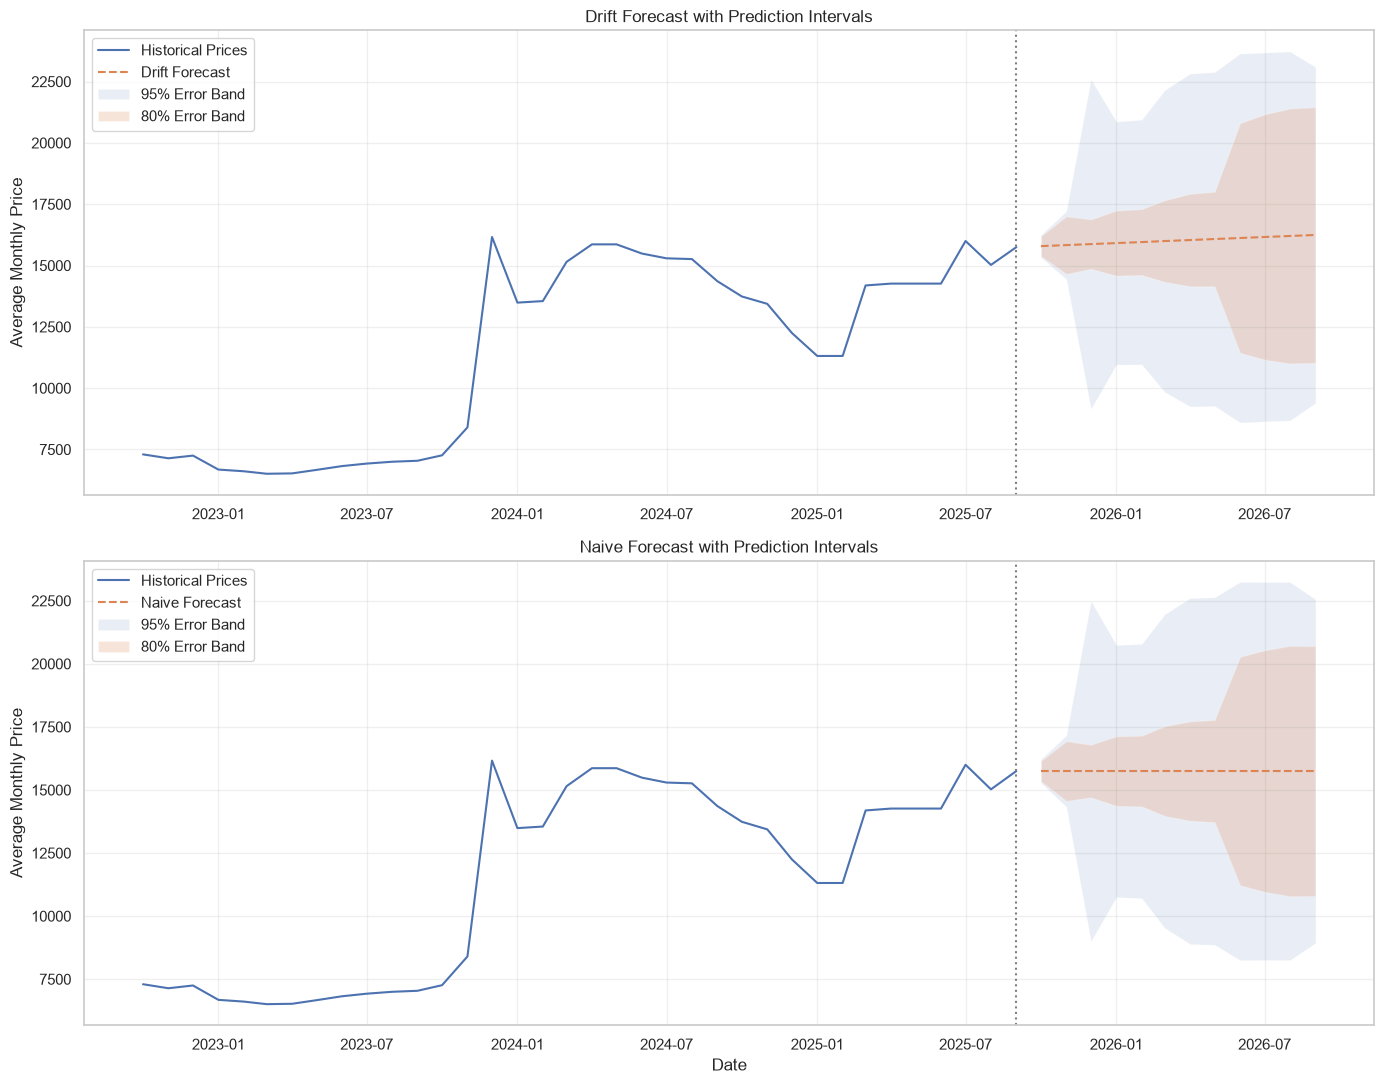

In [97]:
# Compare Drift and Naive forecasts with uncertainty bands

fig, axes = plt.subplots(2, 1, figsize=(14, 11))

# Drift forecast
axes[0].plot(
    ts.tail(36),
    label="Historical Prices"
)

axes[0].plot(
    forecast_dates,
    final_forecast["Drift Forecast"],
    linestyle="--",
    label="Drift Forecast"
)

axes[0].fill_between(
    forecast_dates,
    final_forecast["Drift Lower 95"],
    final_forecast["Drift Upper 95"],
    alpha=0.12,
    label="95% Error Band"
)

axes[0].fill_between(
    forecast_dates,
    final_forecast["Drift Lower 80"],
    final_forecast["Drift Upper 80"],
    alpha=0.22,
    label="80% Error Band"
)

axes[0].set_title("Drift Forecast with Prediction Intervals")
axes[0].set_ylabel("Average Monthly Price")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Naive forecast
axes[1].plot(
    ts.tail(36),
    label="Historical Prices"
)

axes[1].plot(
    forecast_dates,
    final_forecast["Naive Forecast"],
    linestyle="--",
    label="Naive Forecast"
)

axes[1].fill_between(
    forecast_dates,
    final_forecast["Naive Lower 95"],
    final_forecast["Naive Upper 95"],
    alpha=0.12,
    label="95% Error Band"
)

axes[1].fill_between(
    forecast_dates,
    final_forecast["Naive Lower 80"],
    final_forecast["Naive Upper 80"],
    alpha=0.22,
    label="80% Error Band"
)

axes[1].set_title("Naive Forecast with Prediction Intervals")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Average Monthly Price")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.axvline(ts.index[-1], color="gray", linestyle=":")

plt.tight_layout()
plt.show()

In [ ]:
# Save forecast visualizations

OUTPUT_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 1, figsize=(14, 11))

for ax, model, lower80, upper80, lower95, upper95 in [
    (
        axes[0], "Drift",
        "Drift Lower 80", "Drift Upper 80",
        "Drift Lower 95", "Drift Upper 95"
    ),
    (
        axes[1], "Naive",
        "Naive Lower 80", "Naive Upper 80",
        "Naive Lower 95", "Naive Upper 95"
    )
]:
    ax.plot(ts.tail(36), label="Historical Prices")
    ax.plot(
        forecast_dates,
        final_forecast[f"{model} Forecast"],
        linestyle="--",
        label=f"{model} Forecast"
    )
    ax.fill_between(
        forecast_dates,
        final_forecast[lower95],
        final_forecast[upper95],
        alpha=0.12,
        label="95% Error Band"
    )
    ax.fill_between(
        forecast_dates,
        final_forecast[lower80],
        final_forecast[upper80],
        alpha=0.22,
        label="80% Error Band"
    )
    ax.axvline(ts.index[-1], color="gray", linestyle=":")
    ax.set_title(f"{model} Forecast with Prediction Intervals")
    ax.set_ylabel("Average Monthly Price")
    ax.legend()
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Date")

plt.tight_layout()

figure_path = OUTPUT_DIR / "forecast_uncertainty_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Save forecast data

forecast_path = OUTPUT_DIR / "12_month_price_forecast.csv"
final_forecast.to_csv(forecast_path, index=False)

print("Forecast CSV saved:", forecast_path)
print("Forecast graph saved:", figure_path)

### Enhanced Feature Engineering

Additional calendar, lag and rolling statistical features
are evaluated to improve machine learning performance.

In [98]:
# Create enhanced time-series features

def prepare_enhanced_features(history):

    data = pd.DataFrame({"price": history})

    data["month"] = data.index.month
    data["year"] = data.index.year

    data["month_sin"] = np.sin(
        2 * np.pi * data["month"] / 12
    )

    data["month_cos"] = np.cos(
        2 * np.pi * data["month"] / 12
    )

    for lag in [1, 2, 3, 4, 6, 9, 12]:
        data[f"lag_{lag}"] = data["price"].shift(lag)

    previous_price = data["price"].shift(1)

    for window in [3, 6, 12]:
        data[f"rolling_mean_{window}"] = (
            previous_price.rolling(window).mean()
        )

    data["rolling_median_3"] = (
        previous_price.rolling(3).median()
    )

    data["rolling_median_6"] = (
        previous_price.rolling(6).median()
    )

    data["rolling_std_3"] = (
        previous_price.rolling(3).std()
    )

    data["rolling_std_6"] = (
        previous_price.rolling(6).std()
    )

    data["rolling_min_12"] = (
        previous_price.rolling(12).min()
    )

    data["rolling_max_12"] = (
        previous_price.rolling(12).max()
    )

    return data.dropna()

In [99]:
# Generate enhanced features for future dates

def create_enhanced_future_features(history, date):

    features = {
        "month": date.month,
        "year": date.year,
        "month_sin": np.sin(2 * np.pi * date.month / 12),
        "month_cos": np.cos(2 * np.pi * date.month / 12)
    }

    for lag in [1, 2, 3, 4, 6, 9, 12]:
        features[f"lag_{lag}"] = history.iloc[-lag]

    for window in [3, 6, 12]:
        features[f"rolling_mean_{window}"] = (
            history.iloc[-window:].mean()
        )

    features["rolling_median_3"] = (
        history.iloc[-3:].median()
    )

    features["rolling_median_6"] = (
        history.iloc[-6:].median()
    )

    features["rolling_std_3"] = (
        history.iloc[-3:].std()
    )

    features["rolling_std_6"] = (
        history.iloc[-6:].std()
    )

    features["rolling_min_12"] = (
        history.iloc[-12:].min()
    )

    features["rolling_max_12"] = (
        history.iloc[-12:].max()
    )

    return pd.DataFrame([features])

In [100]:
# Recursive forecasting with enhanced features

def enhanced_recursive_forecast(model, history, forecast_dates):

    history = history.copy()
    predictions = []

    for date in forecast_dates:

        X_future = create_enhanced_future_features(
            history,
            date
        )

        prediction = model.predict(X_future)[0]

        predictions.append(prediction)

        history.loc[date] = prediction

    return np.array(predictions)

In [101]:
# Compare original and enhanced ML features

feature_comparison = []

for cutoff in cutoff_dates:

    cutoff_pos = ts.index.get_loc(cutoff)

    history = ts.iloc[:cutoff_pos + 1].copy()
    actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

    if len(actual) != 12:
        continue

    # Original features
    original_data = prepare_ml_features(history)

    X_original = original_data.drop(columns=["price"])
    y_original = original_data["price"]

    # Enhanced features
    enhanced_data = prepare_enhanced_features(history)

    X_enhanced = enhanced_data.drop(columns=["price"])
    y_enhanced = enhanced_data["price"]

    # Random Forest
    rf_original = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=5,
        random_state=42
    )

    rf_original.fit(X_original, y_original)

    rf_original_pred = recursive_forecast(
        rf_original, history, actual.index
    )

    rf_enhanced = RandomForestRegressor(
        n_estimators=300,
        max_depth=5,
        min_samples_split=5,
        random_state=42
    )

    rf_enhanced.fit(X_enhanced, y_enhanced)

    rf_enhanced_pred = enhanced_recursive_forecast(
        rf_enhanced, history, actual.index
    )

    # XGBoost
    xgb_original = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb_original.fit(X_original, y_original)

    xgb_original_pred = recursive_forecast(
        xgb_original, history, actual.index
    )

    xgb_enhanced = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb_enhanced.fit(X_enhanced, y_enhanced)

    xgb_enhanced_pred = enhanced_recursive_forecast(
        xgb_enhanced, history, actual.index
    )

    # Store results
    for name, prediction in [
        ("RF Original", rf_original_pred),
        ("RF Enhanced", rf_enhanced_pred),
        ("XGBoost Original", xgb_original_pred),
        ("XGBoost Enhanced", xgb_enhanced_pred)
    ]:

        metrics = calculate_metrics(
            actual.values,
            prediction
        )

        feature_comparison.append({
            "Cutoff": cutoff,
            "Model": name,
            **metrics
        })

    print("Completed:", cutoff.strftime("%Y-%m"))

Completed: 2017-09
Completed: 2018-09
Completed: 2019-09
Completed: 2020-09
Completed: 2021-09
Completed: 2022-09
Completed: 2023-09


In [102]:
# Compare feature engineering results

feature_comparison_df = pd.DataFrame(feature_comparison)

feature_summary = (
    feature_comparison_df.groupby("Model")[
        ["MAE", "RMSE", "sMAPE"]
    ]
    .mean()
    .sort_values("MAE")
)

display(feature_summary.round(2))

,MAE,RMSE,sMAPE
Model,,,
RF Enhanced,1706.12,1927.02,18.50
RF Original,1805.50,2073.39,19.66
XGBoost Enhanced,1831.61,2011.04,20.13
XGBoost Original,1998.88,2202.77,22.13


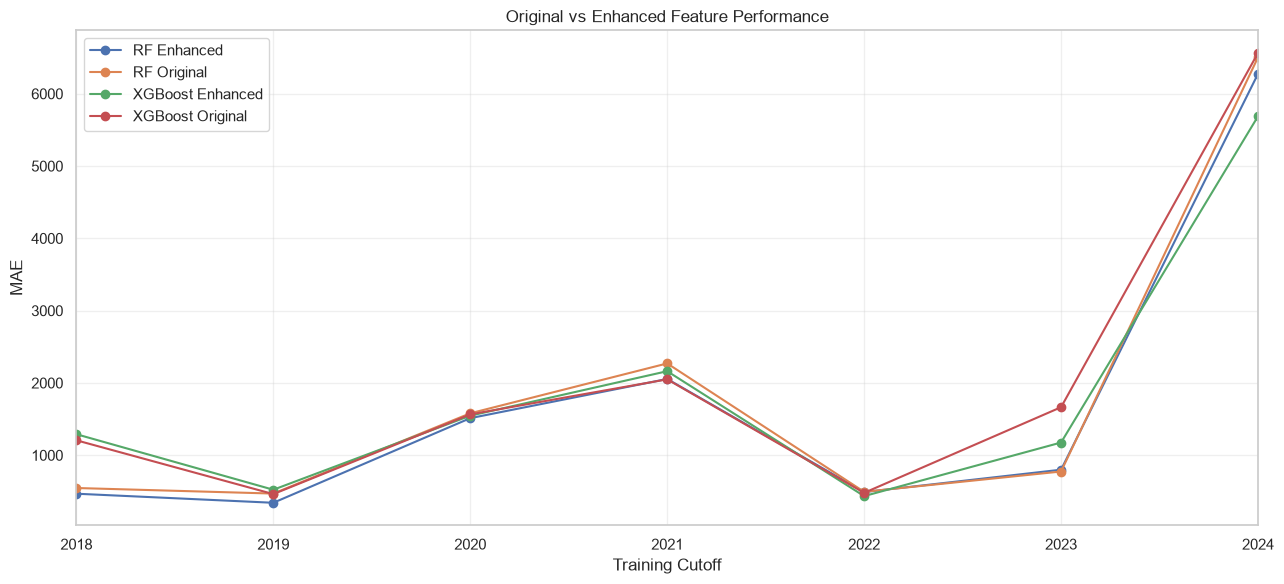

In [103]:
# Compare MAE across feature configurations

feature_pivot = feature_comparison_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
)

feature_pivot.plot(
    figsize=(13, 6),
    marker="o"
)

plt.title("Original vs Enhanced Feature Performance")
plt.xlabel("Training Cutoff")
plt.ylabel("MAE")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

|Model	|Original MAE	|Enhanced MAE|	Reduction|
|---|---|---|---|
|Random Forest	|1,805.50|	1,706.12|	5.50%|
|XGBoost|	1,998.88	|1,831.61	|8.37%|

other metrics:

|Model	|Original RMSE	|Enhanced RMSE	|Original sMAPE	|Enhanced sMAPE|
|---|---|---|---|---|
|Random Forest|	2,073.39|	1,927.02|	19.66%	|18.50%|
|XGBoost|	2,202.77|	2,011.04	|22.13%	|20.13%|

- Both models improved across all three average metrics.
- this does not yet prove that the features improve every historical period. The large errors around the 2023 cutoff remain important.

In [104]:
# Compare feature performance across folds

feature_pivot = feature_comparison_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
)

feature_improvement = pd.DataFrame(index=feature_pivot.index)

feature_improvement["RF Improvement"] = (
    feature_pivot["RF Original"] -
    feature_pivot["RF Enhanced"]
)

feature_improvement["XGBoost Improvement"] = (
    feature_pivot["XGBoost Original"] -
    feature_pivot["XGBoost Enhanced"]
)

display(feature_improvement.round(2))

,RF Improvement,XGBoost Improvement
Cutoff,,
2017-09-01,78.89,-84.07
2018-09-01,127.44,-60.36
2019-09-01,67.25,18.27
2020-09-01,215.11,-112.72
2021-09-01,3.59,45.16
2022-09-01,-24.96,488.49
2023-09-01,228.29,876.13


- Positive values mean the enhanced features reduced MAE.

In [105]:
# Count folds where enhanced features performed better

feature_wins = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Enhanced Feature Wins": [
        (feature_improvement["RF Improvement"] > 0).sum(),
        (feature_improvement["XGBoost Improvement"] > 0).sum()
    ],
    "Total Folds": [len(feature_improvement)] * 2
})

display(feature_wins)

,Model,Enhanced Feature Wins,Total Folds
0,Random Forest,6,7
1,XGBoost,4,7


In [106]:
# Calculate average MAE reduction

improvement_summary = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Original MAE": [
        feature_pivot["RF Original"].mean(),
        feature_pivot["XGBoost Original"].mean()
    ],
    "Enhanced MAE": [
        feature_pivot["RF Enhanced"].mean(),
        feature_pivot["XGBoost Enhanced"].mean()
    ]
})

improvement_summary["MAE Reduction %"] = (
    (
        improvement_summary["Original MAE"] -
        improvement_summary["Enhanced MAE"]
    ) / improvement_summary["Original MAE"] * 100
)

display(improvement_summary.round(2))

,Model,Original MAE,Enhanced MAE,MAE Reduction %
0,Random Forest,1805.50,1706.12,5.50
1,XGBoost,1998.88,1831.61,8.37


In [107]:
# Test Random Forest configurations

rf_configurations = [
    {
        "name": "RF_Original_Config",
        "n_estimators": 300,
        "max_depth": 5,
        "min_samples_split": 5,
        "min_samples_leaf": 1
    },
    {
        "name": "RF_Shallow",
        "n_estimators": 300,
        "max_depth": 3,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },
    {
        "name": "RF_Regularized",
        "n_estimators": 300,
        "max_depth": 4,
        "min_samples_split": 8,
        "min_samples_leaf": 3
    },
    {
        "name": "RF_Deeper",
        "n_estimators": 300,
        "max_depth": 7,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    }
]

rf_config_results = []

for config in rf_configurations:

    fold_errors = []

    for cutoff in cutoff_dates:

        cutoff_pos = ts.index.get_loc(cutoff)

        history = ts.iloc[:cutoff_pos + 1].copy()
        actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

        if len(actual) != 12:
            continue

        feature_data = prepare_enhanced_features(history)

        X_fold = feature_data.drop(columns=["price"])
        y_fold = feature_data["price"]

        model = RandomForestRegressor(
            n_estimators=config["n_estimators"],
            max_depth=config["max_depth"],
            min_samples_split=config["min_samples_split"],
            min_samples_leaf=config["min_samples_leaf"],
            random_state=42
        )

        model.fit(X_fold, y_fold)

        prediction = enhanced_recursive_forecast(
            model, history, actual.index
        )

        metrics = calculate_metrics(
            actual.values, prediction
        )

        fold_errors.append(metrics)

    rf_config_results.append({
        "Configuration": config["name"],
        "MAE": np.mean([x["MAE"] for x in fold_errors]),
        "RMSE": np.mean([x["RMSE"] for x in fold_errors]),
        "sMAPE": np.mean([x["sMAPE"] for x in fold_errors])
    })

rf_config_summary = pd.DataFrame(rf_config_results)

display(
    rf_config_summary.sort_values("MAE").round(2)
)


,Configuration,MAE,RMSE,sMAPE
3,RF_Deeper,1683.78,1897.31,18.27
0,RF_Original_Config,1706.12,1927.02,18.50
2,RF_Regularized,1886.57,2154.13,20.68
1,RF_Shallow,1927.98,2204.68,21.15


In [108]:
# Test XGBoost configurations

xgb_configurations = [
    {
        "name": "XGB_Original_Config",
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.03,
        "min_child_weight": 1,
        "reg_lambda": 1
    },
    {
        "name": "XGB_Shallow",
        "n_estimators": 300,
        "max_depth": 2,
        "learning_rate": 0.03,
        "min_child_weight": 3,
        "reg_lambda": 2
    },
    {
        "name": "XGB_Regularized",
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.02,
        "min_child_weight": 5,
        "reg_lambda": 5
    },
    {
        "name": "XGB_Deeper",
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 2,
        "reg_lambda": 2
    }
]

xgb_config_results = []

for config in xgb_configurations:

    fold_errors = []

    for cutoff in cutoff_dates:

        cutoff_pos = ts.index.get_loc(cutoff)

        history = ts.iloc[:cutoff_pos + 1].copy()
        actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

        if len(actual) != 12:
            continue

        feature_data = prepare_enhanced_features(history)

        X_fold = feature_data.drop(columns=["price"])
        y_fold = feature_data["price"]

        model = XGBRegressor(
            n_estimators=config["n_estimators"],
            max_depth=config["max_depth"],
            learning_rate=config["learning_rate"],
            min_child_weight=config["min_child_weight"],
            reg_lambda=config["reg_lambda"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42
        )

        model.fit(X_fold, y_fold)

        prediction = enhanced_recursive_forecast(
            model, history, actual.index
        )

        metrics = calculate_metrics(
            actual.values, prediction
        )

        fold_errors.append(metrics)

    xgb_config_results.append({
        "Configuration": config["name"],
        "MAE": np.mean([x["MAE"] for x in fold_errors]),
        "RMSE": np.mean([x["RMSE"] for x in fold_errors]),
        "sMAPE": np.mean([x["sMAPE"] for x in fold_errors]),
        "MAE Std": np.std(
            [x["MAE"] for x in fold_errors],
            ddof=1
        )
    })

xgb_config_summary = pd.DataFrame(xgb_config_results)

display(
    xgb_config_summary.sort_values("MAE").round(2)
)

,Configuration,MAE,RMSE,sMAPE,MAE Std
2,XGB_Regularized,1755.93,1964.63,19.07,2188.21
0,XGB_Original_Config,1831.61,2011.04,20.13,1800.53
3,XGB_Deeper,1914.01,2085.76,21.02,1894.07
1,XGB_Shallow,2008.03,2272.05,22.33,2101.39


In [109]:
# Combine Random Forest and XGBoost configurations

rf_config_comparison = rf_config_summary.copy()

rf_config_comparison["MAE Std"] = np.nan

ml_config_comparison = pd.concat(
    [
        rf_config_comparison,
        xgb_config_summary
    ],
    ignore_index=True
)

display(
    ml_config_comparison.sort_values("MAE").round(2)
)

,Configuration,MAE,RMSE,sMAPE,MAE Std
3,RF_Deeper,1683.78,1897.31,18.27,NaN
0,RF_Original_Config,1706.12,1927.02,18.50,NaN
6,XGB_Regularized,1755.93,1964.63,19.07,2188.21
4,XGB_Original_Config,1831.61,2011.04,20.13,1800.53
2,RF_Regularized,1886.57,2154.13,20.68,NaN
7,XGB_Deeper,1914.01,2085.76,21.02,1894.07
1,RF_Shallow,1927.98,2204.68,21.15,NaN
5,XGB_Shallow,2008.03,2272.05,22.33,2101.39


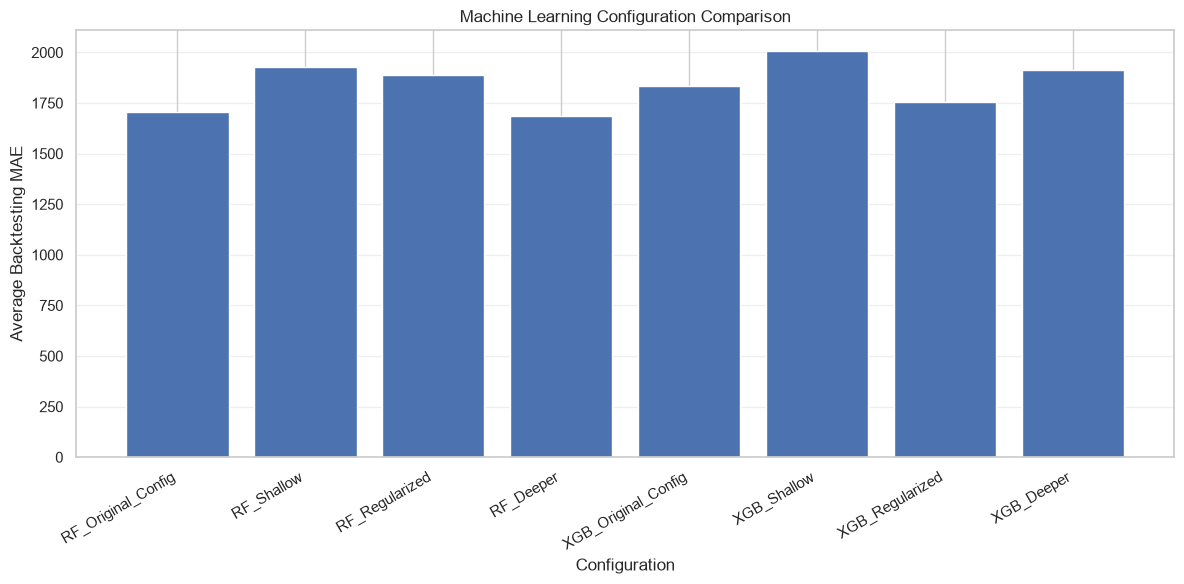

In [110]:
# Compare ML model configurations

plt.figure(figsize=(12, 6))

plt.bar(
    ml_config_comparison["Configuration"],
    ml_config_comparison["MAE"]
)

plt.title("Machine Learning Configuration Comparison")
plt.xlabel("Configuration")
plt.ylabel("Average Backtesting MAE")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Final Candidate Model Comparison

The leading statistical and machine learning models are evaluated
using identical historical cutoffs and a 12-month forecast horizon.

In [111]:
# Compare the four leading forecasting candidates

final_candidate_results = []

for cutoff in cutoff_dates:

    cutoff_pos = ts.index.get_loc(cutoff)

    history = ts.iloc[:cutoff_pos + 1].copy()
    actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

    if len(actual) != 12:
        continue

    # Statistical forecasts
    naive_pred = np.repeat(history.iloc[-1], 12)

    drift_rate = (
        history.iloc[-1] - history.iloc[0]
    ) / (len(history) - 1)

    drift_pred = (
        history.iloc[-1]
        + drift_rate * np.arange(1, 13)
    )

    # Enhanced features
    feature_data = prepare_enhanced_features(history)

    X_fold = feature_data.drop(columns=["price"])
    y_fold = feature_data["price"]

    # Random Forest Deeper
    rf_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=7,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )

    rf_model.fit(X_fold, y_fold)

    rf_pred = enhanced_recursive_forecast(
        rf_model, history, actual.index
    )

    # XGBoost Regularized
    xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.02,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb_model.fit(X_fold, y_fold)

    xgb_pred = enhanced_recursive_forecast(
        xgb_model, history, actual.index
    )

    predictions = {
        "Naive": naive_pred,
        "Drift": drift_pred,
        "RF Deeper": rf_pred,
        "XGB Regularized": xgb_pred
    }

    for model_name, prediction in predictions.items():

        metrics = calculate_metrics(
            actual.values,
            prediction
        )

        final_candidate_results.append({
            "Cutoff": cutoff,
            "Model": model_name,
            **metrics
        })

final_candidate_df = pd.DataFrame(final_candidate_results)

display(final_candidate_df.round(2))

,Cutoff,Model,MAE,RMSE,sMAPE
0,2017-09-01,Naive,412.75,501.91,5.99
1,2017-09-01,Drift,451.47,548.87,6.53
2,2017-09-01,RF Deeper,442.52,578.51,6.30
3,2017-09-01,XGB Regularized,779.68,872.73,10.86
4,2018-09-01,Naive,489.67,604.37,6.55
5,2018-09-01,Drift,448.20,550.46,5.99
6,2018-09-01,RF Deeper,373.97,436.12,5.00
7,2018-09-01,XGB Regularized,444.91,565.27,5.95
8,2019-09-01,Naive,1525.67,1602.29,16.19
9,2019-09-01,Drift,1411.62,1488.76,14.88


- Random Forest Deeper has the lowest average MAE, RMSE and sMAPE.
- It also wins the most individual folds.
- Naive performs better than the ML models in some periods, so the ML model is not consistently superior.

In [112]:
# Summarize model performance across folds

final_candidate_summary = (
    final_candidate_df.groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Median_MAE=("MAE", "median"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_sMAPE=("sMAPE", "mean")
    )
    .sort_values("Mean_MAE")
)

display(final_candidate_summary.round(2))

,Mean_MAE,Median_MAE,Std_MAE,Mean_RMSE,Mean_sMAPE
Model,,,,,
RF Deeper,1683.78,824.64,2061.41,1897.31,18.27
XGB Regularized,1755.93,779.68,2188.21,1964.63,19.07
Drift,1764.08,743.93,2311.63,2091.44,19.29
Naive,1773.93,718.42,2328.42,2087.45,19.40


In [114]:
# Count the lowest MAE in each backtesting fold

candidate_pivot = final_candidate_df.pivot(
    index="Cutoff",
    columns="Model",
    values="MAE"
)

fold_wins = (
    candidate_pivot.idxmin(axis=1)
    .value_counts()
    .rename_axis("Model")
    .reset_index(name="Fold Wins")
)

display(fold_wins)

,Model,Fold Wins
0,RF Deeper,3
1,Naive,2
2,Drift,1
3,XGB Regularized,1


In [115]:
# Evaluate forecast bias across backtesting folds

bias_results = []

for cutoff in cutoff_dates:

    cutoff_pos = ts.index.get_loc(cutoff)

    history = ts.iloc[:cutoff_pos + 1].copy()
    actual = ts.iloc[cutoff_pos + 1:cutoff_pos + 13]

    if len(actual) != 12:
        continue

    naive_pred = np.repeat(history.iloc[-1], 12)

    drift_rate = (
        history.iloc[-1] - history.iloc[0]
    ) / (len(history) - 1)

    drift_pred = (
        history.iloc[-1]
        + drift_rate * np.arange(1, 13)
    )

    feature_data = prepare_enhanced_features(history)

    X_fold = feature_data.drop(columns=["price"])
    y_fold = feature_data["price"]

    rf_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=7,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )

    rf_model.fit(X_fold, y_fold)

    rf_pred = enhanced_recursive_forecast(
        rf_model, history, actual.index
    )

    xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.02,
        min_child_weight=5,
        reg_lambda=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    xgb_model.fit(X_fold, y_fold)

    xgb_pred = enhanced_recursive_forecast(
        xgb_model, history, actual.index
    )

    predictions = {
        "Naive": naive_pred,
        "Drift": drift_pred,
        "RF Deeper": rf_pred,
        "XGB Regularized": xgb_pred
    }

    for model_name, prediction in predictions.items():

        errors = actual.values - prediction

        bias_results.append({
            "Cutoff": cutoff,
            "Model": model_name,
            "Mean Bias": np.mean(errors),
            "Mean Absolute Error": np.mean(np.abs(errors))
        })

bias_df = pd.DataFrame(bias_results)

bias_summary = (
    bias_df.groupby("Model")
    .agg(
        Mean_Bias=("Mean Bias", "mean"),
        Mean_Absolute_Bias=("Mean Bias", lambda x: np.mean(np.abs(x)))
    )
    .sort_values("Mean_Absolute_Bias")
)

display(bias_summary.round(2))

,Mean_Bias,Mean_Absolute_Bias
Model,,
RF Deeper,898.95,1385.26
XGB Regularized,1037.95,1399.73
Naive,1030.90,1630.33
Drift,961.70,1642.22


RF Deeper as our leading candidate

Model,Drift,Naive,RF Deeper,XGB Regularized
Cutoff,,,,
2017-09-01,-402.87,-331.75,-402.49,-779.68
2018-09-01,197.29,264.67,-278.63,51.27
2019-09-01,1411.62,1525.67,1482.99,1569.32
2020-09-01,-1824.52,-1657.25,-196.33,-18.89
2021-09-01,743.93,718.42,357.26,405.31
2022-09-01,-154.44,-109.00,-824.64,-467.69
2023-09-01,6760.90,6805.58,6154.49,6505.98


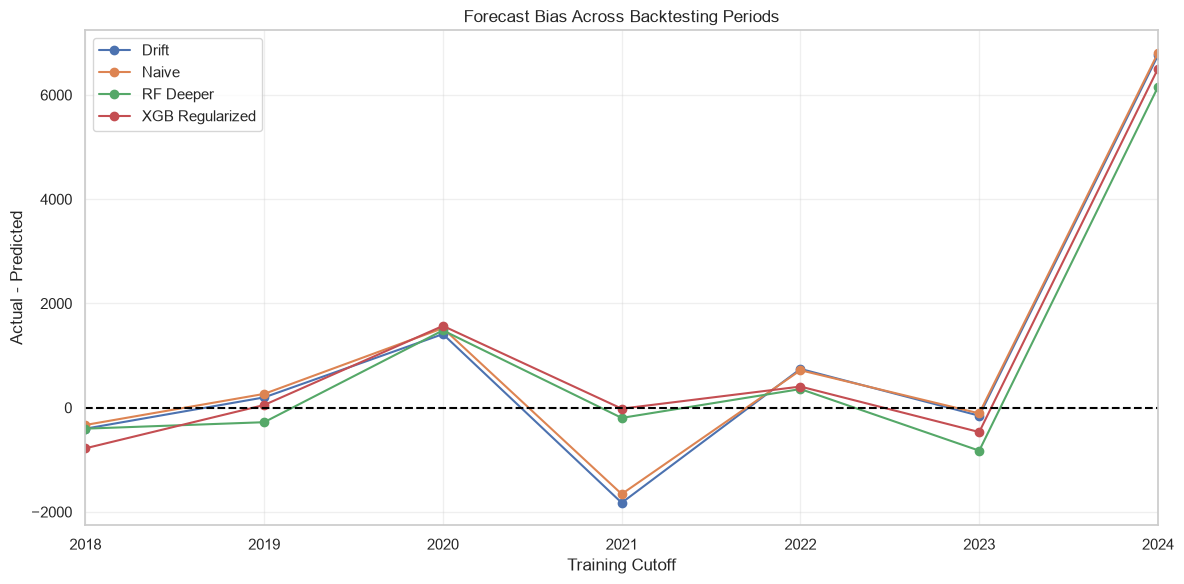

In [116]:
# Compare forecast bias across historical folds

bias_pivot = bias_df.pivot(
    index="Cutoff",
    columns="Model",
    values="Mean Bias"
)

display(bias_pivot.round(2))

bias_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Forecast Bias Across Backtesting Periods")
plt.xlabel("Training Cutoff")
plt.ylabel("Actual - Predicted")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

- The problem is not a constant underprediction problem. It is primarily a problem of changing price behaviour.
- The sudden increase explains much of the large positive bias in the final fold.

In [117]:
# Calculate relative forecast bias

bias_percentage = bias_df.copy()

bias_percentage["Mean Actual Price"] = (
    bias_percentage["Cutoff"].map(
        lambda cutoff: ts.loc[
            cutoff + pd.DateOffset(months=1):
            cutoff + pd.DateOffset(months=12)
        ].mean()
    )
)

bias_percentage["Bias %"] = (
    bias_percentage["Mean Bias"]
    / bias_percentage["Mean Actual Price"]
    * 100
)

display(
    bias_percentage[
        ["Cutoff", "Model", "Mean Bias", "Bias %"]
    ].round(2)
)

,Cutoff,Model,Mean Bias,Bias %
0,2017-09-01,Naive,-331.75,-4.86
1,2017-09-01,Drift,-402.87,-5.90
2,2017-09-01,RF Deeper,-402.49,-5.89
3,2017-09-01,XGB Regularized,-779.68,-11.41
4,2018-09-01,Naive,264.67,3.55
5,2018-09-01,Drift,197.29,2.64
6,2018-09-01,RF Deeper,-278.63,-3.73
7,2018-09-01,XGB Regularized,51.27,0.69
8,2019-09-01,Naive,1525.67,15.09
9,2019-09-01,Drift,1411.62,13.96


Model,Drift,Naive,RF Deeper,XGB Regularized
Cutoff,,,,
2017-09-01,451.47,412.75,442.52,779.68
2018-09-01,448.20,489.67,373.97,444.91
2019-09-01,1411.62,1525.67,1482.99,1569.32
2020-09-01,2260.84,2219.58,1997.17,2072.07
2021-09-01,743.93,718.42,510.65,450.42
2022-09-01,271.61,245.83,824.64,469.15
2023-09-01,6760.90,6805.58,6154.49,6505.98


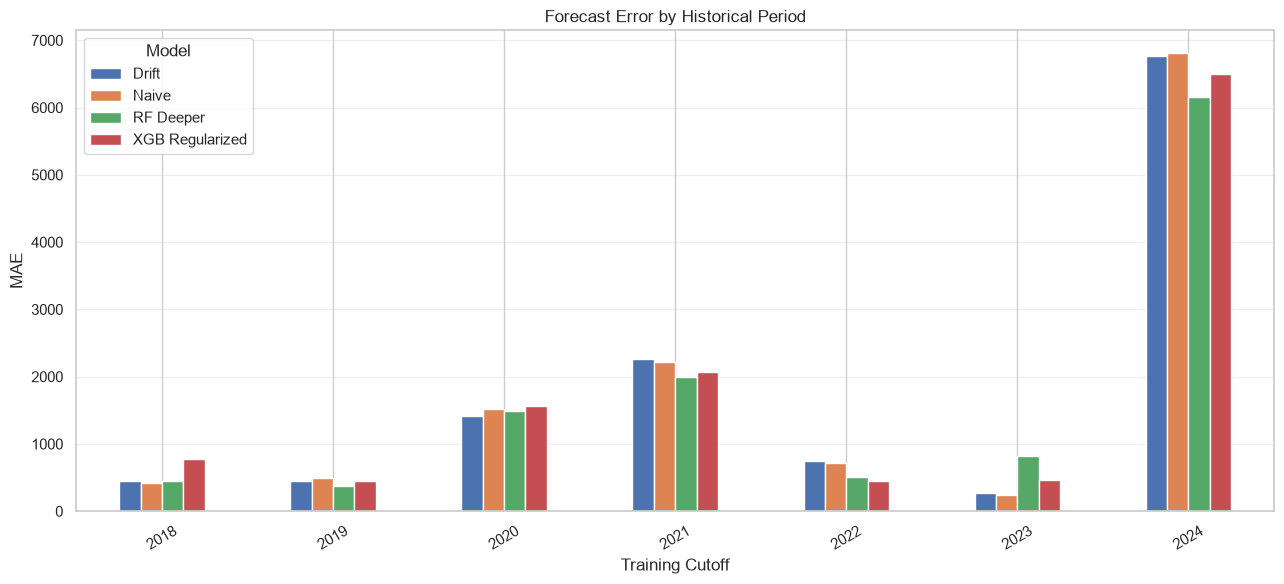

In [118]:
# Identify periods with the largest forecast errors

error_analysis = (
    final_candidate_df.pivot(
        index="Cutoff",
        columns="Model",
        values="MAE"
    )
)

display(error_analysis.round(2))

error_analysis.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Forecast Error by Historical Period")
plt.xlabel("Training Cutoff")
plt.ylabel("MAE")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Direct Forecasting

In [119]:
# Prepare the monthly price series
data = df[['date', 'avg_monthly_price']].copy()
data['date'] = pd.to_datetime(data['date'])
data = data.sort_values('date').set_index('date')

price_series = data['avg_monthly_price'].astype(float)

def get_direct_features(origin_date, target_date):
    row = {
        'price': price_series.loc[origin_date],
        'target_month': target_date.month,
        'target_year': target_date.year
    }

    for lag in [1, 2, 3, 6, 12]:
        lag_date = origin_date - pd.DateOffset(months=lag)
        row[f'lag_{lag}'] = price_series.loc[lag_date]

    for window in [3, 6, 12]:
        values = [
            price_series.loc[origin_date - pd.DateOffset(months=i)]
            for i in range(window)
        ]
        row[f'rolling_mean_{window}'] = np.mean(values)

    row['rolling_std_3'] = np.std([
        price_series.loc[origin_date - pd.DateOffset(months=i)]
        for i in range(3)
    ], ddof=1)

    return row

In [120]:
cutoffs = pd.to_datetime([
    '2017-09-01',
    '2018-09-01',
    '2019-09-01',
    '2020-09-01',
    '2021-09-01',
    '2022-09-01',
    '2023-09-01'
])

direct_results = []

for cutoff in cutoffs:

    for horizon in range(1, 13):

        target_date = cutoff + pd.DateOffset(months=horizon)

        if target_date not in price_series.index:
            continue

        X_train = []
        y_train = []

        for origin_date in price_series.index:

            train_target_date = origin_date + pd.DateOffset(months=horizon)

            if train_target_date > cutoff:
                break

            if train_target_date not in price_series.index:
                continue

            if origin_date < price_series.index[12]:
                continue

            X_train.append(
                get_direct_features(origin_date, train_target_date)
            )
            y_train.append(price_series.loc[train_target_date])

        if len(X_train) < 24:
            continue

        X_train = pd.DataFrame(X_train)
        X_predict = pd.DataFrame([
            get_direct_features(cutoff, target_date)
        ])

        model = RandomForestRegressor(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        prediction = model.predict(X_predict)[0]
        actual = price_series.loc[target_date]

        naive_prediction = price_series.loc[cutoff]

        direct_results.append({
            'Cutoff': cutoff,
            'Horizon': horizon,
            'Date': target_date,
            'Actual': actual,
            'RF_Direct': prediction,
            'Naive': naive_prediction
        })

direct_results_df = pd.DataFrame(direct_results)

print("Direct forecasting completed.")
print("Total predictions:", len(direct_results_df))
print("Historical folds:", direct_results_df['Cutoff'].nunique())

display(direct_results_df.head(12))

Direct forecasting completed.
Total predictions: 84
Historical folds: 7


,Cutoff,Horizon,Date,Actual,RF_Direct,Naive
0,2017-09-01,1,2017-10-01,7188.0,7250.684458,7163.0
1,2017-09-01,2,2017-11-01,7013.0,7255.425368,7163.0
2,2017-09-01,3,2017-12-01,6800.0,7429.727343,7163.0
3,2017-09-01,4,2018-01-01,6763.0,7793.611089,7163.0
4,2017-09-01,5,2018-02-01,6550.0,7740.870522,7163.0
5,2017-09-01,6,2018-03-01,6500.0,7892.473280,7163.0
6,2017-09-01,7,2018-04-01,6362.0,7913.891974,7163.0
7,2017-09-01,8,2018-05-01,6487.0,7841.697128,7163.0
8,2017-09-01,9,2018-06-01,6362.0,7897.825553,7163.0
9,2017-09-01,10,2018-07-01,7550.0,7806.687970,7163.0


In [121]:
def calculate_metrics(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    smape = np.mean(
        200 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted))
    )

    bias = np.mean(actual - predicted)

    return pd.Series({
        'MAE': mae,
        'RMSE': rmse,
        'sMAPE': smape,
        'Mean_Bias': bias
    })


direct_metrics = pd.DataFrame({
    'RF Direct': calculate_metrics(
        direct_results_df['Actual'],
        direct_results_df['RF_Direct']
    ),
    'Naive': calculate_metrics(
        direct_results_df['Actual'],
        direct_results_df['Naive']
    )
}).T

display(direct_metrics.round(2))

,MAE,RMSE,sMAPE,Mean_Bias
RF Direct,2021.19,2736.89,22.72,446.81
Naive,1773.93,3145.28,19.40,1030.90


In [122]:
horizon_metrics = []

for horizon, group in direct_results_df.groupby('Horizon'):

    metrics = calculate_metrics(
        group['Actual'],
        group['RF_Direct']
    )

    horizon_metrics.append({
        'Horizon': horizon,
        'MAE': metrics['MAE'],
        'RMSE': metrics['RMSE'],
        'sMAPE': metrics['sMAPE'],
        'Mean_Bias': metrics['Mean_Bias']
    })

horizon_metrics_df = pd.DataFrame(horizon_metrics)

display(horizon_metrics_df.round(2))

,Horizon,MAE,RMSE,sMAPE,Mean_Bias
0,1,163.67,192.54,2.19,77.67
1,2,741.11,798.74,9.43,124.49
2,3,2170.54,3341.38,23.04,867.34
3,4,2170.94,2653.75,25.17,464.27
4,5,2374.04,2757.74,27.77,397.55
5,6,2855.49,3380.02,31.40,807.68
6,7,2849.22,3385.38,31.31,790.30
7,8,2740.06,3261.71,29.64,899.91
8,9,2401.46,2971.75,27.35,71.86
9,10,2020.80,2759.66,22.74,175.44


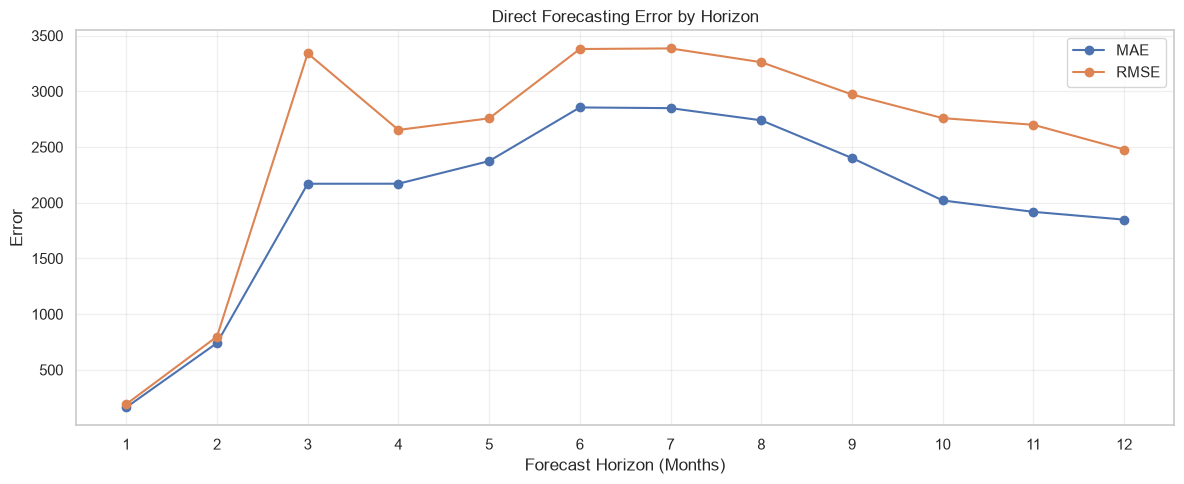

In [123]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    horizon_metrics_df['Horizon'],
    horizon_metrics_df['MAE'],
    marker='o',
    label='MAE'
)

ax.plot(
    horizon_metrics_df['Horizon'],
    horizon_metrics_df['RMSE'],
    marker='o',
    label='RMSE'
)

ax.set_title('Direct Forecasting Error by Horizon')
ax.set_xlabel('Forecast Horizon (Months)')
ax.set_ylabel('Error')
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [124]:
fold_metrics = []

for cutoff, group in direct_results_df.groupby('Cutoff'):

    metrics = calculate_metrics(
        group['Actual'],
        group['RF_Direct']
    )

    fold_metrics.append({
        'Cutoff': cutoff,
        'MAE': metrics['MAE'],
        'RMSE': metrics['RMSE'],
        'sMAPE': metrics['sMAPE'],
        'Mean_Bias': metrics['Mean_Bias']
    })

direct_fold_metrics = pd.DataFrame(fold_metrics)

display(direct_fold_metrics.round(2))

,Cutoff,MAE,RMSE,sMAPE,Mean_Bias
0,2017-09-01,916.45,1046.67,12.64,-916.45
1,2018-09-01,1685.19,1800.14,20.06,-1685.19
2,2019-09-01,1964.30,2111.77,21.50,1964.30
3,2020-09-01,2330.82,2551.83,29.81,301.69
4,2021-09-01,1212.33,1574.90,20.07,-1180.84
5,2022-09-01,699.51,828.36,9.70,-695.61
6,2023-09-01,5339.74,5827.54,45.27,5339.74


The September 2023 result is particularly important: the sudden price increase was difficult for every model to anticipate.

- Not performed good

#### Rolling training windows

In [125]:
def run_direct_backtest(window_months=None):

    results = []

    for cutoff in cutoffs:

        for horizon in range(1, 13):

            target_date = cutoff + pd.DateOffset(months=horizon)

            if target_date not in price_series.index:
                continue

            X_train = []
            y_train = []

            for origin_date in price_series.index:

                train_target_date = origin_date + pd.DateOffset(months=horizon)

                if train_target_date > cutoff:
                    break

                if origin_date < price_series.index[12]:
                    continue

                if window_months is not None:
                    window_start = cutoff - pd.DateOffset(
                        months=window_months
                    )

                    if origin_date < window_start:
                        continue

                X_train.append(
                    get_direct_features(origin_date, train_target_date)
                )

                y_train.append(price_series.loc[train_target_date])

            if len(X_train) < 24:
                continue

            X_train = pd.DataFrame(X_train)

            X_predict = pd.DataFrame([
                get_direct_features(cutoff, target_date)
            ])

            model = RandomForestRegressor(
                n_estimators=300,
                max_depth=8,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train, y_train)

            prediction = model.predict(X_predict)[0]
            actual = price_series.loc[target_date]

            results.append({
                'Cutoff': cutoff,
                'Horizon': horizon,
                'Actual': actual,
                'Prediction': prediction
            })

    return pd.DataFrame(results)


rolling_results = {
    '36 Months': run_direct_backtest(36),
    '60 Months': run_direct_backtest(60),
    '84 Months': run_direct_backtest(84)
}

print("Rolling window experiments completed.")

for name, result in rolling_results.items():
    print(name, ":", len(result), "predictions")

Rolling window experiments completed.
36 Months : 84 predictions
60 Months : 84 predictions
84 Months : 84 predictions


In [126]:
window_comparison = []

window_comparison.append({
    'Training Window': 'Expanding',
    **calculate_metrics(
        direct_results_df['Actual'],
        direct_results_df['RF_Direct']
    ).to_dict()
})

for name, result in rolling_results.items():

    window_comparison.append({
        'Training Window': name,
        **calculate_metrics(
            result['Actual'],
            result['Prediction']
        ).to_dict()
    })

window_comparison_df = pd.DataFrame(window_comparison)

display(
    window_comparison_df
    .set_index('Training Window')
    .round(2)
)

,MAE,RMSE,sMAPE,Mean_Bias
Training Window,,,,
Expanding,2021.19,2736.89,22.72,446.81
36 Months,2469.71,3482.60,28.45,532.22
60 Months,2062.07,3078.16,23.30,605.32
84 Months,2342.11,3205.60,26.49,423.57


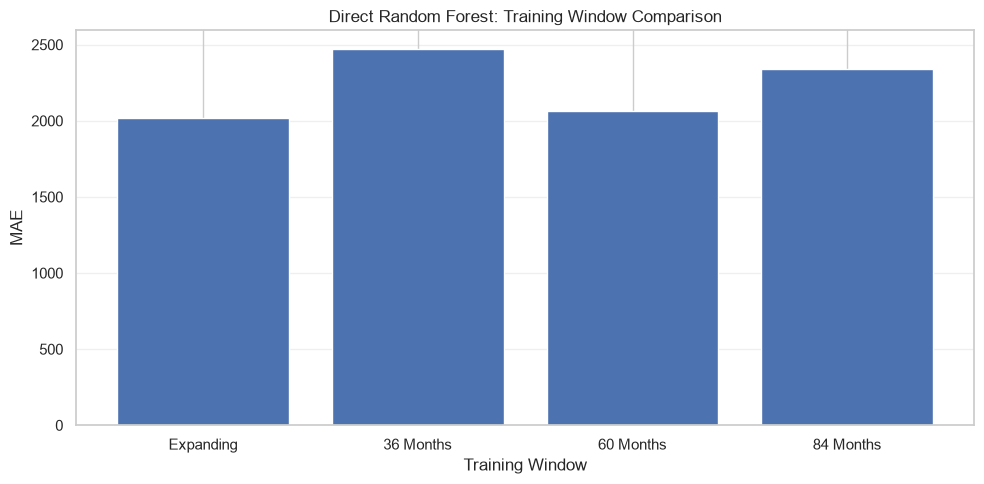

In [127]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    window_comparison_df['Training Window'],
    window_comparison_df['MAE']
)

ax.set_title('Direct Random Forest: Training Window Comparison')
ax.set_xlabel('Training Window')
ax.set_ylabel('MAE')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- None of the rolling windows improved its performance.
- restricting the training history is not helping this dataset. It does not prove that older data is always useful


In [128]:
# Calculate recent price movements
latest_price = price_series.iloc[-1]
previous_month_price = price_series.iloc[-2]
previous_year_price = price_series.iloc[-13]

monthly_change = latest_price - previous_month_price
monthly_change_pct = (monthly_change / previous_month_price) * 100

yearly_change = latest_price - previous_year_price
yearly_change_pct = (yearly_change / previous_year_price) * 100

recent_volatility = price_series.tail(12).std()
recent_average = price_series.tail(12).mean()

business_summary = pd.DataFrame({
    'Metric': [
        'Latest Price',
        'Monthly Price Change',
        'Monthly Change (%)',
        'Yearly Price Change',
        'Yearly Change (%)',
        'Last 12 Months Average',
        'Last 12 Months Standard Deviation'
    ],
    'Value': [
        latest_price,
        monthly_change,
        monthly_change_pct,
        yearly_change,
        yearly_change_pct,
        recent_average,
        recent_volatility
    ]
})

display(business_summary.round(2))

,Metric,Value
0,Latest Price,15750.00
1,Monthly Price Change,725.00
2,Monthly Change (%),4.83
3,Yearly Price Change,1387.00
4,Yearly Change (%),9.66
5,Last 12 Months Average,13817.00
6,Last 12 Months Standard Deviation,1532.71


In [129]:
recent_data = price_series.tail(12)

recent_trend = np.polyfit(
    np.arange(len(recent_data)),
    recent_data.values,
    1
)[0]

if recent_trend > 0:
    price_direction = 'Increasing'
elif recent_trend < 0:
    price_direction = 'Decreasing'
else:
    price_direction = 'Stable'

print("Recent price direction:", price_direction)
print("Average monthly trend:", round(recent_trend, 2))
print("Recent price volatility:", round(recent_volatility, 2))

Recent price direction: Increasing
Average monthly trend: 301.89
Recent price volatility: 1532.71


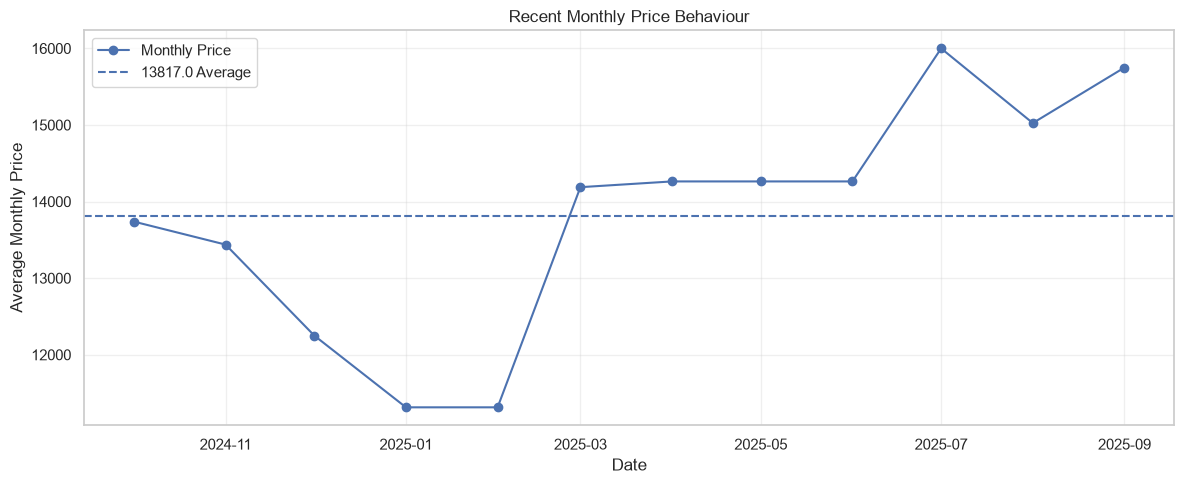

In [132]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    recent_data.index,
    recent_data.values,
    marker='o',
    label='Monthly Price'
)

ax.axhline(
    recent_average,
    linestyle='--',
    label=f"{recent_average} Average"
)

ax.set_title('Recent Monthly Price Behaviour')
ax.set_xlabel('Date')
ax.set_ylabel('Average Monthly Price')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Business Insights and Actionable Recommendations

### Key Findings

1. The latest observed monthly price is 15,750.
2. The price increased by 4.83% compared with the previous month.
3. The year-over-year increase is 9.66%.
4. The latest price is above the trailing 12-month average of 13,817.
5. The recent price series exhibits substantial variation.
6. Forecast uncertainty increases with the prediction horizon.

### Business Implications

- Monitor price increases to identify potential procurement cost pressure.
- Avoid making large purchasing commitments based only on a single forecast.
- Use prediction intervals to plan conservative, expected and high-cost scenarios.
- Review actual prices against forecasts every month.
- Investigate substantial deviations before changing procurement or pricing strategies.

### Important Limitation

The dataset had only dates and average monthly prices. It does not contain product identity, inventory, demand, supplier costs, location or profit margins.

Therefore, the recommendations are general price-monitoring and planning strategies rather than product-specific operational decisions.

### Reusable Prediction Pipeline

In [134]:
# Inspect available forecasting objects and results

print("Available forecasting objects:")

for name in [
    'best_model',
    'final_model',
    'rf_model',
    'rf_direct_model',
    'selected_model',
    'forecast_results',
    'final_forecast',
    'future_dates',
    'forecast_df',
    'price_data',
    'df'
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Available forecasting objects:
rf_model: RandomForestRegressor
final_forecast: DataFrame
df: DataFrame


In [135]:
# Inspect the trained Random Forest model

print("MODEL DETAILS")
print("-" * 50)

print("Model type:", type(rf_model).__name__)
print("Number of input features:", rf_model.n_features_in_)

print("\nModel parameters:")
for parameter, value in rf_model.get_params().items():
    print(f"{parameter}: {value}")

print("\nFeature names used during training:")

if hasattr(rf_model, "feature_names_in_"):
    print(rf_model.feature_names_in_.tolist())
else:
    print("Feature names are not stored in this model.")

print("\nMODEL OUTPUT")
print("-" * 50)

print("Final forecast shape:", final_forecast.shape)
print("Final forecast columns:")
print(final_forecast.columns.tolist())

print("\nHistorical dataset columns:")
print(df.columns.tolist())

MODEL DETAILS
--------------------------------------------------
Model type: RandomForestRegressor
Number of input features: 20

Model parameters:
bootstrap: True
ccp_alpha: 0.0
criterion: squared_error
max_depth: 7
max_features: 1.0
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 2
min_samples_split: 5
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 300
n_jobs: None
oob_score: False
random_state: 42
verbose: 0
warm_start: False

Feature names used during training:
['month', 'year', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_6', 'lag_9', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_median_3', 'rolling_median_6', 'rolling_std_3', 'rolling_std_6', 'rolling_min_12', 'rolling_max_12']

MODEL OUTPUT
--------------------------------------------------
Final forecast shape: (12, 14)
Final forecast columns:
['Date', 'Naive Forecast', 'Drift Forecast', 'Drift Change', 'Drift Change %', 'Drift

In [136]:
print("MODEL VALIDATION")
print("-" * 50)

print("Number of features expected:",
      rf_model.n_features_in_)

print("Model fitted successfully:",
      hasattr(rf_model, "estimators_"))

print("Number of trees:",
      len(rf_model.estimators_)
      if hasattr(rf_model, "estimators_")
      else "Not available")

print("\nModel training configuration:")
print(rf_model)

MODEL VALIDATION
--------------------------------------------------
Number of features expected: 20
Model fitted successfully: True
Number of trees: 300

Model training configuration:
RandomForestRegressor(max_depth=7, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=300, random_state=42)


In [137]:
# Identify the exact feature dataset used to train Random Forest

required_features = list(rf_model.feature_names_in_)

print("SEARCHING FOR FEATURE DATASETS")
print("=" * 60)

for name, obj in globals().copy().items():

    if isinstance(obj, pd.DataFrame):

        matching_features = [
            col for col in required_features
            if col in obj.columns
        ]

        if len(matching_features) >= 15:

            print(f"\nDataset: {name}")
            print("Shape:", obj.shape)
            print("Matching features:", len(matching_features))
            print("Columns:", obj.columns.tolist())

            if 'price' in obj.columns:
                print("Target column: price")

            elif 'avg_monthly_price' in obj.columns:
                print("Target column: avg_monthly_price")

SEARCHING FOR FEATURE DATASETS

Dataset: feature_data
Shape: (213, 21)
Matching features: 20
Columns: ['price', 'month', 'year', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_6', 'lag_9', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_median_3', 'rolling_median_6', 'rolling_std_3', 'rolling_std_6', 'rolling_min_12', 'rolling_max_12']
Target column: price

Dataset: X_fold
Shape: (213, 20)
Matching features: 20
Columns: ['month', 'year', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_6', 'lag_9', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_median_3', 'rolling_median_6', 'rolling_std_3', 'rolling_std_6', 'rolling_min_12', 'rolling_max_12']

Dataset: enhanced_data
Shape: (213, 21)
Matching features: 20
Columns: ['price', 'month', 'year', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_6', 'lag_9', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_medi

In [138]:
# Verify feature dataset structure and temporal alignment

print("FEATURE DATASET VALIDATION")
print("=" * 60)

print("\nDataset shape:", feature_data.shape)

print("\nIndex information:")
print("Index type:", type(feature_data.index).__name__)
print("Index name:", feature_data.index.name)
print("First index:", feature_data.index[0])
print("Last index:", feature_data.index[-1])

print("\nFirst five records:")
display(feature_data.head())

print("\nLast five records:")
display(feature_data.tail())

print("\nMissing values:")
display(feature_data.isnull().sum())

print("\nFeature order matches trained model:",
      list(rf_model.feature_names_in_) ==
      [col for col in feature_data.columns if col != 'price'])

print("\nTarget summary:")
display(feature_data['price'].describe())

FEATURE DATASET VALIDATION

Dataset shape: (213, 21)

Index information:
Index type: DatetimeIndex
Index name: date
First index: 2006-01-01 00:00:00
Last index: 2023-09-01 00:00:00

First five records:


,price,month,year,month_sin,month_cos,lag_1,lag_2,lag_3,lag_4,lag_6,...,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_median_3,rolling_median_6,rolling_std_3,rolling_std_6,rolling_min_12,rolling_max_12
date,,,,,,,,,,,,,,,,,,,,,
2006-01-01,4000,1,2006,0.500000,8.660254e-01,3813.0,4665.0,4562.0,4899.0,4919.0,...,5500.0,4346.666667,4667.833333,5072.500000,4562.0,4782.0,465.029390,466.903166,3813.0,5876.0
2006-02-01,4755,2,2006,0.866025,5.000000e-01,4000.0,3813.0,4665.0,4562.0,5149.0,...,5476.0,4159.333333,4514.666667,4947.500000,4000.0,4613.5,447.790502,516.168448,3813.0,5876.0
2006-03-01,4176,3,2006,1.000000,6.123234e-17,4755.0,4000.0,3813.0,4665.0,4899.0,...,5466.0,4189.333333,4449.000000,4887.416667,4000.0,4613.5,498.724707,438.556268,3813.0,5876.0
2006-04-01,3500,4,2006,0.866025,-5.000000e-01,4176.0,4755.0,4000.0,3813.0,4562.0,...,5487.0,4310.333333,4328.500000,4779.916667,4176.0,4369.0,395.019409,386.410533,3813.0,5876.0
2006-05-01,6000,5,2006,0.500000,-8.660254e-01,3500.0,4176.0,4755.0,4000.0,4665.0,...,5876.0,4143.666667,4151.500000,4614.333333,4176.0,4088.0,628.124457,487.951125,3500.0,5876.0



Last five records:


,price,month,year,month_sin,month_cos,lag_1,lag_2,lag_3,lag_4,lag_6,...,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_median_3,rolling_median_6,rolling_std_3,rolling_std_6,rolling_min_12,rolling_max_12
date,,,,,,,,,,,,,,,,,,,,,
2023-05-01,6669,5,2023,5.000000e-01,-8.660254e-01,6525.0,6510.0,6612.0,6681.0,7141.0,...,5015.0,6549.000000,6786.500000,6493.500000,6525.0,6646.5,55.072679,324.628249,5015.0,7300.0
2023-06-01,6823,6,2023,1.224647e-16,-1.000000e+00,6669.0,6525.0,6510.0,6612.0,7250.0,...,5600.0,6568.000000,6707.833333,6631.333333,6525.0,6640.5,87.789521,274.926475,5600.0,7300.0
2023-07-01,6925,7,2023,-5.000000e-01,-8.660254e-01,6823.0,6669.0,6525.0,6510.0,6681.0,...,5856.0,6672.333333,6636.666667,6733.250000,6669.0,6640.5,149.027962,115.631599,5856.0,7300.0
2023-08-01,7000,8,2023,-8.660254e-01,-5.000000e-01,6925.0,6823.0,6669.0,6525.0,6612.0,...,6450.0,6805.666667,6677.333333,6822.333333,6823.0,6640.5,128.877203,166.193462,6450.0,7300.0
2023-09-01,7040,9,2023,-1.000000e+00,-1.836970e-16,7000.0,6925.0,6823.0,6669.0,6510.0,...,6982.0,6916.000000,6742.000000,6868.166667,6925.0,6746.0,88.842557,206.327894,6510.0,7300.0



Missing values:


price               0
month               0
year                0
month_sin           0
month_cos           0
lag_1               0
lag_2               0
lag_3               0
lag_4               0
lag_6               0
lag_9               0
lag_12              0
rolling_mean_3      0
rolling_mean_6      0
rolling_mean_12     0
rolling_median_3    0
rolling_median_6    0
rolling_std_3       0
rolling_std_6       0
rolling_min_12      0
rolling_max_12      0
dtype: int64


Feature order matches trained model: True

Target summary:


count      213.000000
mean      7413.065728
std       1985.619728
min       3500.000000
25%       6327.000000
50%       7187.000000
75%       8875.000000
max      12075.000000
Name: price, dtype: float64

In [139]:
# Inspect feature relationships for the most recent observations

verification_columns = [
    'price',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_12',
    'rolling_mean_3',
    'rolling_mean_6',
    'rolling_mean_12',
    'rolling_std_3'
]

display(feature_data[verification_columns].tail(10))

,price,lag_1,lag_2,lag_3,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3
date,,,,,,,,,
2022-12-01,7250,7141.0,7300.0,6982.0,5102.0,7141.000000,6554.833333,5775.333333,159.000000
2023-01-01,6681,7250.0,7141.0,7300.0,5218.0,7230.333333,6829.833333,5954.333333,81.303956
2023-02-01,6612,6681.0,7250.0,7141.0,4865.0,7024.000000,6967.333333,6076.250000,302.004967
2023-03-01,6510,6612.0,6681.0,7250.0,4956.0,6847.666667,6994.333333,6221.833333,350.134736
2023-04-01,6525,6510.0,6612.0,6681.0,4819.0,6601.000000,6915.666667,6351.333333,86.029065
2023-05-01,6669,6525.0,6510.0,6612.0,5015.0,6549.000000,6786.500000,6493.500000,55.072679
2023-06-01,6823,6669.0,6525.0,6510.0,5600.0,6568.000000,6707.833333,6631.333333,87.789521
2023-07-01,6925,6823.0,6669.0,6525.0,5856.0,6672.333333,6636.666667,6733.250000,149.027962
2023-08-01,7000,6925.0,6823.0,6669.0,6450.0,6805.666667,6677.333333,6822.333333,128.877203


In [140]:
# Check the feature engineering and model training functions

import inspect

print("AVAILABLE FEATURE FUNCTIONS")
print("=" * 50)

for function_name in [
    'prepare_enhanced_features',
    'create_enhanced_features',
    'build_features'
]:
    if function_name in globals():
        function = globals()[function_name]

        print(f"\nFunction: {function_name}")
        print(inspect.getsource(function))

print("\nTRAINING PERIOD CHECK")
print("=" * 50)

print("Original dataset ends:", df['date'].max())
print("Feature dataset ends:", feature_data.index.max())
print("Feature dataset records:", len(feature_data))

print("\nCurrent model feature count:", rf_model.n_features_in_)
print("Current model tree count:", len(rf_model.estimators_))

AVAILABLE FEATURE FUNCTIONS

Function: prepare_enhanced_features
def prepare_enhanced_features(history):

    data = pd.DataFrame({"price": history})

    data["month"] = data.index.month
    data["year"] = data.index.year

    data["month_sin"] = np.sin(
        2 * np.pi * data["month"] / 12
    )

    data["month_cos"] = np.cos(
        2 * np.pi * data["month"] / 12
    )

    for lag in [1, 2, 3, 4, 6, 9, 12]:
        data[f"lag_{lag}"] = data["price"].shift(lag)

    previous_price = data["price"].shift(1)

    for window in [3, 6, 12]:
        data[f"rolling_mean_{window}"] = (
            previous_price.rolling(window).mean()
        )

    data["rolling_median_3"] = (
        previous_price.rolling(3).median()
    )

    data["rolling_median_6"] = (
        previous_price.rolling(6).median()
    )

    data["rolling_std_3"] = (
        previous_price.rolling(3).std()
    )

    data["rolling_std_6"] = (
        previous_price.rolling(6).std()
    )

    data["rolling_min_12"] 

In [141]:
# Prepare the complete historical dataset
full_ts = (
    df.assign(date=pd.to_datetime(df["date"]))
      .sort_values("date")
      .set_index("date")["avg_monthly_price"]
      .astype(float)
)

# Generate the final model features
final_feature_data = prepare_enhanced_features(full_ts)

final_X = final_feature_data.drop(columns=["price"])
final_y = final_feature_data["price"]

# Train the selected Random Forest model
final_rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=7,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

final_rf_model.fit(final_X, final_y)

print("FINAL MODEL TRAINING COMPLETED")
print("-" * 45)
print("Training records:", len(final_X))
print("Features:", final_X.shape[1])
print("First training date:", final_X.index.min())
print("Last training date:", final_X.index.max())
print("Trees:", len(final_rf_model.estimators_))
print("Model type:", type(final_rf_model).__name__)
print("Feature order verified:",
      list(final_rf_model.feature_names_in_) == list(final_X.columns))

FINAL MODEL TRAINING COMPLETED
---------------------------------------------
Training records: 237
Features: 20
First training date: 2006-01-01 00:00:00
Last training date: 2025-09-01 00:00:00
Trees: 300
Model type: RandomForestRegressor
Feature order verified: True


In [142]:
# Save the final model and its metadata
import joblib
import json
from pathlib import Path

model_dir = Path.cwd() / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "price_forecasting_rf_model.joblib"
metadata_path = model_dir / "model_metadata.json"

joblib.dump(final_rf_model, model_path)

metadata = {
    "model_name": "Random Forest Deeper",
    "model_type": "RandomForestRegressor",
    "training_start": str(final_X.index.min().date()),
    "training_end": str(final_X.index.max().date()),
    "training_records": len(final_X),
    "feature_count": final_X.shape[1],
    "features": list(final_X.columns),
    "n_estimators": 300,
    "max_depth": 7,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "target": "avg_monthly_price"
}

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("MODEL SAVED SUCCESSFULLY")
print("Model path:", model_path)
print("Metadata path:", metadata_path)
print("Model file exists:", model_path.exists())
print("Metadata file exists:", metadata_path.exists())

MODEL SAVED SUCCESSFULLY
Model path: d:\BECAME_DEVELOPER\PriceForecastingW2A\notebooks\models\price_forecasting_rf_model.joblib
Metadata path: d:\BECAME_DEVELOPER\PriceForecastingW2A\notebooks\models\model_metadata.json
Model file exists: True
Metadata file exists: True


In [143]:
# Load and verify the saved model
loaded_model = joblib.load(model_path)

sample_input = final_X.tail(1)

loaded_prediction = loaded_model.predict(sample_input)

print("MODEL LOADING VERIFIED")
print("-" * 40)
print("Loaded model:", type(loaded_model).__name__)
print("Input features:", sample_input.shape[1])
print("Prediction:", round(loaded_prediction[0], 2))
print("Original model prediction:",
      round(final_rf_model.predict(sample_input)[0], 2))
print("Prediction matches:",
      np.allclose(
          loaded_prediction,
          final_rf_model.predict(sample_input)
      ))

MODEL LOADING VERIFIED
----------------------------------------
Loaded model: RandomForestRegressor
Input features: 20
Prediction: 15401.74
Original model prediction: 15401.74
Prediction matches: True
